# 1. Título

**Cinema brasileiro em dados: obras, empresas e salas de exibição registradas na ANCINE**

DCC011 Introdução a Banco de Dados (turma TB), UFMG, 2026/2. Trabalho Prático 2: relatório final.

# 2. Membros (nome e número de matrícula)

- Fabrício Chaves da Costa (2022039968)
- **[demais membros a confirmar]**

# 3. Descrição dos dados (qual a URL? qual o domínio? como os dados foram processados?)

## 3.1 Domínio e fontes

O domínio é o **registro público do setor audiovisual brasileiro** mantido pela Agência Nacional do Cinema (ANCINE).
A agência registra as empresas que atuam no setor (agentes econômicos), as atividades econômicas que cada uma exerce,
as obras audiovisuais brasileiras não publicitárias (cada uma recebe um Certificado de Produto Brasileiro, o **CPB**),
os projetos de fomento indireto (leis federais de incentivo, identificados pelo número **SALIC**) e o parque exibidor
(complexos de cinema e suas salas). Os conjuntos estão no portal dados.gov.br, com atualização mensal, em CSV
(UTF-8, separador `;`), e não em SQL:

| Conjunto no dados.gov.br | Arquivo baixado (dados.ancine.gov.br/dados-abertos/) |
|:--|:--|
| [Obras não publicitárias brasileiras registradas na ANCINE](https://dados.gov.br/dados/conjuntos-dados/obras-nao-publicitarias-brasileiras-registradas-na-ancine) | `obras-nao-pub-brasileiras-csv.zip` (um CSV por ano de emissão do CPB, 2002 a 2026) |
| [Agentes econômicos regulares registrados na ANCINE](https://dados.gov.br/dados/conjuntos-dados/agentes-economicos-regulares-registrados-na-ancine) | `agentes-economicos-regulares.csv` |
| [Atividades econômicas dos agentes regulares](https://dados.gov.br/dados/conjuntos-dados/atividades-economicas-dos-agentes-regulares-registrados-na-ancine) | `atividades-economicas-agentes-regulares.csv` |
| [Salas de exibição e complexos registrados na ANCINE](https://dados.gov.br/dados/conjuntos-dados/salas-de-exibicao-e-complexos-registrados-na-ancine) | `salas-de-exibicao-e-complexos.csv` |
| [Obras com fomento indireto aprovado (leis de incentivo federais)](https://dados.gov.br/dados/conjuntos-dados/obras-nao-publicitarias-brasileiras-com-fomento-indireto-aprovado-na-ancine-leis-de-incentivo-federa) | `obras-nao-pub-brasileiras-fomento-indireto.csv` |
| Produtoras independentes (complementar) | `produtoras-independentes.csv` |

Os arquivos se ligam pelo **CNPJ** das empresas, pelo **registro ANCINE** e pelo **CPB** das obras.

**Ambiente.** Python 3 com `pandas`, `matplotlib` e `graphviz` (arquivo `requirements.txt`), o módulo `sqlite3` da
biblioteca padrão e o executável `dot` do Graphviz para os diagramas. A célula abaixo baixa os arquivos para a pasta
`dados/` apenas quando ainda não existem, e o banco é criado do zero em `tp2.db` a cada execução.

In [1]:
import os
import re
import sys
import sqlite3
import unicodedata
import urllib.request
import zipfile
from pathlib import Path

import graphviz
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from IPython.display import HTML, display

os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ.get("PATH", "")
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)


def mostrar_svg(caminho, classe):
    svg = Path(caminho).read_text(encoding="utf-8")
    svg = svg[svg.index("<svg"):]
    svg = re.sub(r'<svg width="[^"]+" height="[^"]+"', '<svg width="100%"', svg, count=1)
    display(HTML(f'<div class="{classe}">{svg}</div>'))


DADOS = Path("dados")
DIAGRAMAS = Path("diagramas")
BANCO = Path("tp2.db")
BASE = "https://dados.ancine.gov.br/dados-abertos/"
ARQUIVOS = {
    "obras": "obras-nao-pub-brasileiras-csv.zip",
    "agentes": "agentes-economicos-regulares.csv",
    "atividades": "atividades-economicas-agentes-regulares.csv",
    "salas": "salas-de-exibicao-e-complexos.csv",
    "fomento": "obras-nao-pub-brasileiras-fomento-indireto.csv",
    "produtoras": "produtoras-independentes.csv",
}

DADOS.mkdir(exist_ok=True)
DIAGRAMAS.mkdir(exist_ok=True)
for arquivo in ARQUIVOS.values():
    destino = DADOS / arquivo
    if not destino.exists():
        urllib.request.urlretrieve(BASE + arquivo, destino)

pasta_obras = DADOS / "obras"
if not pasta_obras.exists():
    with zipfile.ZipFile(DADOS / ARQUIVOS["obras"]) as z:
        z.extractall(pasta_obras)

pd.DataFrame(
    [(a, round((DADOS / a).stat().st_size / 1e6, 1)) for a in ARQUIVOS.values()],
    columns=["arquivo", "tamanho (MB)"],
)

,arquivo,tamanho (MB)
0,obras-nao-pub-brasileiras-csv.zip,2.7
1,agentes-economicos-regulares.csv,3.1
2,atividades-economicas-agentes-regulares.csv,19.5
3,salas-de-exibicao-e-complexos.csv,2.2
4,obras-nao-pub-brasileiras-fomento-indireto.csv,0.1
5,produtoras-independentes.csv,0.9


## 3.2 Carga dos arquivos brutos no SQLite

Seguindo a abordagem da aula de EDA em SQL, os CSVs são lidos com `pandas` **sem nenhuma conversão** (todas as colunas
como texto, vazios como string vazia) e gravados como tabelas `bruto_*` no próprio `tp2.db`. A partir daqui, perfil,
dependências funcionais, limpeza e normalização são feitos em SQL. Os 25 CSVs anuais de obras têm o mesmo cabeçalho e
são empilhados em uma única tabela `bruto_obras`.

In [2]:
if BANCO.exists():
    BANCO.unlink()
con = sqlite3.connect(BANCO)


def sql(consulta):
    return pd.read_sql_query(consulta, con)


def ler_csv(caminho):
    return pd.read_csv(caminho, sep=";", dtype=str, keep_default_na=False, encoding="utf-8")


brutos = {
    "bruto_obras": pd.concat([ler_csv(f) for f in sorted(pasta_obras.glob("*.csv"))], ignore_index=True),
    "bruto_agentes": ler_csv(DADOS / ARQUIVOS["agentes"]),
    "bruto_atividades": ler_csv(DADOS / ARQUIVOS["atividades"]),
    "bruto_salas": ler_csv(DADOS / ARQUIVOS["salas"]),
    "bruto_fomento": ler_csv(DADOS / ARQUIVOS["fomento"]),
    "bruto_produtoras": ler_csv(DADOS / ARQUIVOS["produtoras"]),
}
for tabela, df in brutos.items():
    df.to_sql(tabela, con, index=False)

sql(" UNION ALL ".join(
    f"SELECT '{t}' AS tabela, COUNT(*) AS linhas, {len(df.columns)} AS colunas FROM {t}" for t, df in brutos.items()
))

,tabela,linhas,colunas
0,bruto_obras,63255,18
1,bruto_agentes,18704,11
2,bruto_atividades,146963,5
3,bruto_salas,6419,32
4,bruto_fomento,3199,3
5,bruto_produtoras,12232,6


O perfil abaixo lista, para cada coluna de cada arquivo, o número de valores distintos, o percentual de vazios e um
exemplo. Ele é a base das decisões de chave, de dependência funcional e de limpeza das seções seguintes.

In [3]:
perfil = " UNION ALL ".join(
    f"""SELECT '{t.removeprefix("bruto_")}' AS arquivo, '{c}' AS coluna,
           COUNT(DISTINCT "{c}") AS distintos,
           ROUND(100.0 * SUM(TRIM("{c}") = '') / COUNT(*), 1) AS pct_vazio,
           substr(MAX("{c}"), 1, 40) AS exemplo
       FROM {t}"""
    for t, df in brutos.items() for c in df.columns
)
sql(perfil)

,arquivo,coluna,distintos,pct_vazio,exemplo
0,obras,TITULO_ORIGINAL,58551,0.0,…É SÓ FECHAR OS OLHOS!
1,obras,CPB,63255,0.0,B600566000000
2,obras,DATA_EMISSAO_CPB,5723,0.0,31/12/2024
3,obras,SITUACAO_OBRA,2,0.0,DEFERIDO_SUS
4,obras,TIPO_OBRA,11,0.0,VÍDEOMUSICAL
5,obras,SUBTIPO_OBRA,5,56.4,Vídeoaula
6,obras,CLASSIFICACAO_OBRA,4,0.0,NÃO INFORMADO
7,obras,ORGANIZACAO_TEMPORAL,5,0.0,SERIADA EM TEMPORADA ÚNICA
8,obras,DURACAO_TOTAL_MINUTOS,3824,0.0,"996,3"
9,obras,QUANTIDADE_EPISODIOS,382,72.8,999


**O que cada arquivo contém (na carga de 03/11/2026).**

- **Obras** (63.255 linhas, 18 colunas): uma linha por obra com CPB emitido entre 2002 e 2026. O `CPB` é único.
  Traz título, data de emissão do CPB, situação, tipo (ficção, documentário, animação etc.), subtipo, classificação,
  organização temporal (seriada ou não), duração, episódios, anos de produção, segmento de destinação inicial,
  coprodução internacional e o requerente (nome, CNPJ, UF e município). Em 11.200 obras o requerente é pessoa física e
  a coluna `CNPJ_REQUERENTE` vem com o texto `PESSOA FÍSICA`.
- **Agentes econômicos regulares** (18.704 linhas, 11 colunas): uma linha por empresa regular, com registro ANCINE,
  data de registro, razão social, CNPJ, data de constituição, UF, município e código IBGE, classificação do agente,
  natureza jurídica e se é brasileira independente. `CNPJ` e `REGISTRO_ANCINE` são únicos.
- **Atividades econômicas** (146.963 linhas, 5 colunas): uma linha por par empresa e atividade (CNAE por descrição),
  marcada como `PRINCIPAL` ou `SECUNDARIA`. Repete a razão social e o registro da empresa em cada linha.
- **Salas e complexos** (6.419 linhas, 32 colunas): uma linha por sala (37 linhas descrevem complexos sem sala), com os dados da sala (situação, data de
  início, assentos e acessibilidade), do complexo onde ela fica (nome, endereço, município, UF, situação, itinerante)
  e da empresa exibidora (nome, registro, CNPJ, situação e grupo exibidor) repetidos em cada linha.
- **Fomento indireto** (3.199 linhas, 3 colunas): pares obra (`CPB`) e projeto (`NUMERO_SALIC`) com o título da obra.
- **Produtoras independentes** (12.232 linhas, 6 colunas): empresas com nível de classificação da produtora (1 a 5),
  usado só como atributo complementar das empresas.

## 3.3 Processo bottom-up: dependências funcionais

O enunciado pede um projeto **bottom-up**: partir das tabelas planas, descobrir as dependências funcionais (DFs) e
normalizar. Cada DF candidata `X → Y` é testada no próprio SQLite: ela vale nos dados quando nenhum valor de
`X` aparece com mais de um valor de `Y`, isto é, quando a consulta
`SELECT X FROM t GROUP BY X HAVING COUNT(DISTINCT Y) > 1` volta vazia. Quando `X` ou `Y` têm mais de uma coluna,
elas são concatenadas com o separador `'|'`, para que valores diferentes não se confundam ao serem colados (sem ele,
`'AB' || 'C'` e `'A' || 'BC'` dariam o mesmo texto). A tabela abaixo mostra o número de violações de
cada DF testada.

In [4]:
def com_separador(colunas):
    return colunas.replace(" || ", " || '|' || ")


dfs = [
    ("bruto_obras", "CPB", "TITULO_ORIGINAL || TIPO_OBRA || CNPJ_REQUERENTE"),
    ("bruto_obras", "CNPJ_REQUERENTE", "REQUERENTE"),
    ("bruto_obras", "CNPJ_REQUERENTE", "MUNICIPIO_REQUERENTE || UF_REQUERENTE"),
    ("bruto_agentes", "CNPJ", "RAZAO_SOCIAL || REGISTRO_ANCINE || NATUREZA_JURIDICA"),
    ("bruto_agentes", "REGISTRO_ANCINE", "CNPJ"),
    ("bruto_agentes", "CODIGO_MUNICIPIO_IBGE", "MUNICIPIO || UF"),
    ("bruto_atividades", "CNPJ", "RAZAO_SOCIAL || REGISTRO_ANCINE"),
    ("bruto_atividades", "CNPJ", "ATIVIDADE_ECONOMICA"),
    ("bruto_atividades", "CNPJ || ATIVIDADE_ECONOMICA", "CLASSIFICACAO_ATIVIDADE"),
    ("bruto_salas", "REGISTRO_SALA", "NOME_SALA || ASSENTOS_SALA || SITUACAO_SALA"),
    ("bruto_salas", "REGISTRO_SALA", "REGISTRO_COMPLEXO"),
    ("bruto_salas", "REGISTRO_COMPLEXO", "NOME_COMPLEXO || ENDERECO_COMPLEXO || MUNICIPIO_COMPLEXO || UF_COMPLEXO"),
    ("bruto_salas", "REGISTRO_COMPLEXO", "SITUACAO_COMPLEXO || COMPLEXO_ITINERANTE || OPERACAO_USUAL"),
    ("bruto_salas", "REGISTRO_COMPLEXO", "CNPJ_EXIBIDOR"),
    ("bruto_salas", "CNPJ_EXIBIDOR", "NOME_EXIBIDOR || REGISTRO_EXIBIDOR || SITUACAO_EXIBIDOR"),
    ("bruto_salas", "CNPJ_EXIBIDOR", "NOME_GRUPO_EXIBIDOR"),
    ("bruto_fomento", "CPB", "TITULO_ORIGINAL"),
    ("bruto_fomento", "CPB", "NUMERO_SALIC"),
]
sql(" UNION ALL ".join(
    f"""SELECT '{t.removeprefix("bruto_")}' AS arquivo,
           '{x.replace(" || ", ", ")}  →  {y.replace(" || ", ", ")}' AS dependencia,
           (SELECT COUNT(*) FROM (SELECT 1 FROM {t} GROUP BY {com_separador(x)}
                                 HAVING COUNT(DISTINCT {com_separador(y)}) > 1)) AS violacoes"""
    for t, x, y in dfs
))

,arquivo,dependencia,violacoes
0,obras,"CPB → TITULO_ORIGINAL, TIPO_OBRA, CNPJ_REQUERENTE",0
1,obras,CNPJ_REQUERENTE → REQUERENTE,1
2,obras,"CNPJ_REQUERENTE → MUNICIPIO_REQUERENTE, UF_REQUERENTE",1
3,agentes,"CNPJ → RAZAO_SOCIAL, REGISTRO_ANCINE, NATUREZA_JURIDICA",0
4,agentes,REGISTRO_ANCINE → CNPJ,0
5,agentes,"CODIGO_MUNICIPIO_IBGE → MUNICIPIO, UF",1
6,atividades,"CNPJ → RAZAO_SOCIAL, REGISTRO_ANCINE",0
7,atividades,CNPJ → ATIVIDADE_ECONOMICA,17365
8,atividades,"CNPJ, ATIVIDADE_ECONOMICA → CLASSIFICACAO_ATIVIDADE",38
9,salas,"REGISTRO_SALA → NOME_SALA, ASSENTOS_SALA, SITUACAO_SALA",0


**Leitura do resultado.**

- `CPB` determina todos os atributos da obra, e `CNPJ_REQUERENTE` determina o nome, a UF e o município do requerente
  (as violações dessa linha são só do valor `PESSOA FÍSICA`, que não identifica ninguém). Logo, no arquivo de obras,
  `CPB → CNPJ_REQUERENTE → MUNICIPIO_REQUERENTE` é uma **dependência transitiva**.
- Em agentes, `CNPJ` e `REGISTRO_ANCINE` são chaves candidatas, e `CODIGO_MUNICIPIO_IBGE → MUNICIPIO, UF` é outra
  dependência transitiva (a única violação é o código vazio de 7 linhas).
- Em atividades, a chave é o par `(CNPJ, ATIVIDADE_ECONOMICA)`: `CNPJ → ATIVIDADE_ECONOMICA` falha (é um fato
  multivalorado, origem do relacionamento M:N), e `RAZAO_SOCIAL` e `REGISTRO_ANCINE` dependem só de parte da chave.
  O par não determina a classificação em 38 casos: a mesma atividade aparece como principal e como secundária.
- Em salas, o registro do complexo determina nome, endereço, município, situação e exibidor; o CNPJ do exibidor
  determina nome, registro, situação e **grupo exibidor**. Então
  `REGISTRO_SALA → REGISTRO_COMPLEXO → CNPJ_EXIBIDOR → NOME_GRUPO_EXIBIDOR` é uma cadeia transitiva. A DF
  `REGISTRO_SALA → REGISTRO_COMPLEXO` só falha para o registro vazio, que aparece em 37 linhas sem sala (tratado na
  limpeza).
- No fomento, a chave é `(CPB, NUMERO_SALIC)`: uma obra pode ter mais de um projeto (`CPB → NUMERO_SALIC` falha), e o
  título depende só do CPB.

## 3.4 Normalização (1FN, 2FN e 3FN)

- **1FN.** Todos os valores já são atômicos: a lista de atividades de uma empresa vem em linhas separadas, e o endereço
  do complexo vem em colunas separadas (logradouro, número, complemento, bairro, CEP), mantidas como atributos
  simples. Os 25 arquivos anuais de obras viram uma relação só.
- **2FN.** Remove dependências parciais das chaves compostas. Em atividades, razão social e registro saem para
  `empresa` (dependem só do CNPJ) e a descrição vai para `atividade_economica`, ficando em `empresa_atividade` só a
  chave e a classificação (principal ou secundária). No fomento, o título sai (já está em `obra`) e o número SALIC vira
  a entidade `projeto_fomento`, ficando `obra_fomento` só com o par de chaves.
- **3FN.** Remove dependências transitivas. Requerente sai de `obra` para `empresa` (fica só a chave estrangeira
  `cnpj_requerente`); município e UF saem de `empresa` e `complexo` para `municipio`; complexo sai de `sala`;
  exibidor sai de `complexo` para `empresa`, junto com o **grupo exibidor** e a situação do exibidor, porque dependem
  do CNPJ do exibidor e não do complexo.

| Colunas de origem | Tabela de destino |
|:--|:--|
| Obras: `CPB`, título, data do CPB, situação, tipo, subtipo, classificação, organização temporal, duração, episódios, anos de produção, segmento, coprodução | `obra` |
| Obras: `CNPJ_REQUERENTE` (pessoa jurídica) | `obra.cnpj_requerente` → `empresa` |
| Obras: município e UF do requerente pessoa física | `obra.id_municipio_requerente_pf` → `municipio` |
| Obras: nome, UF e município do requerente pessoa jurídica | `empresa` (razão social e município) |
| Agentes: todas as colunas, menos município e UF | `empresa` |
| Agentes, obras e salas: município, UF e código IBGE | `municipio` |
| Produtoras independentes: nível da produtora | `empresa.nivel_produtora_independente` |
| Atividades: descrição | `atividade_economica` (com segmento derivado) |
| Atividades: CNPJ, descrição e classificação | `empresa_atividade` |
| Salas: colunas `*_SALA`, acessibilidade | `sala` |
| Salas: colunas `*_COMPLEXO`, operação usual | `complexo` |
| Salas: nome, registro, situação e grupo do exibidor | `empresa` |
| Fomento: `NUMERO_SALIC` | `projeto_fomento` |
| Fomento: `CPB`, `NUMERO_SALIC` | `obra_fomento` |

Colunas descartadas: `TITULO_ORIGINAL` do fomento (redundante), `CNPJ_SALA` (CNPJ de filial informado por sala, sem
uso nas investigações) e o nome do requerente pessoa física (não identifica a pessoa e não é usado nas análises).

## 3.5 Limpeza

A limpeza é feita em SQL, em tabelas temporárias `limpo_*` derivadas das brutas:

- **CNPJ**: removidos `.`, `/` e `-`, ficando os 14 dígitos (todos os CNPJs dos arquivos têm o formato padrão). O texto
  `PESSOA FÍSICA` vira `NULL`.
- **Datas** `dd/mm/aaaa` viram ISO `aaaa-mm-dd`, só quando casam com o padrão (vazio vira `NULL`).
- **Números**: duração com vírgula decimal vira `REAL`; assentos e episódios viram `INTEGER`; valores negativos de
  assentos (`-1`, marcador de "não informado") viram `NULL`; anos de produção fora de 1890 a 2026 (por exemplo `83`)
  viram `NULL`.
- **SIM/NÃO** viram 1/0; `NÃO INFORMADO`, `-` e vazios viram `NULL`.
- **Municípios**: os três arquivos grafam o mesmo município de formas diferentes (por exemplo `JOAO PESSOA` sem o
  código IBGE e `JOÃO PESSOA` com ele). A função `chave_municipio`, registrada no SQLite, remove acentos e apóstrofos e troca
  hífens por espaço (assim `SANTA BARBARA DOESTE` e `SANTA BÁRBARA D'OESTE` coincidem); municípios com a mesma chave e UF são o mesmo. O nome exibido é a grafia mais frequente e o código IBGE vem
  dos agentes, quando existe; os 6 códigos fictícios do arquivo de agentes (8888888 e 9999969 a 9999982) são
  descartados.
- **CPB**: 2 obras têm CPB com 13 caracteres em vez de 14 (`B600566000000` e `B130174300000`). Como é o
  identificador oficial e não colide com nenhum outro, o valor é mantido e a restrição aceita 13 ou 14 caracteres.
- **Duplicatas**: não há linhas repetidas em nenhum arquivo. As 38 duplicatas de par empresa e atividade ficam com a
  classificação `PRINCIPAL`.
- **Complexos sem sala**: 37 linhas do arquivo de salas têm registro de sala vazio e situação `NÃO ENCONTRADA`. Elas
  descrevem complexos sem sala cadastrada: entram em `complexo`, mas não geram tupla em `sala`.
- **Empresas**: a tabela `empresa` une, pelo CNPJ, (i) os 18.704 agentes regulares, (ii) os requerentes pessoa
  jurídica das obras que não estão entre os regulares (razão social e município vêm do arquivo de obras) e (iii) os
  exibidores que não estão em nenhum dos dois (razão social e registro vêm do arquivo de salas). A coluna
  `agente_regular` distingue o primeiro grupo; os atributos que só existem no cadastro de agentes ficam `NULL` nos
  demais.

In [5]:
def chave_municipio(nome):
    if nome is None:
        return None
    sem_acento = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode()
    for caractere in "'´`":
        sem_acento = sem_acento.replace(caractere, "")
    sem_acento = sem_acento.replace("-", " ")
    return " ".join(sem_acento.upper().split()) or None


con.create_function("chave_municipio", 1, chave_municipio, deterministic=True)


def data_iso(coluna):
    return (f"CASE WHEN {coluna} GLOB '[0-3][0-9]/[01][0-9]/[12][0-9][0-9][0-9]' "
            f"THEN substr({coluna}, 7, 4) || '-' || substr({coluna}, 4, 2) || '-' || substr({coluna}, 1, 2) END")


def so_digitos(coluna):
    return f"REPLACE(REPLACE(REPLACE({coluna}, '.', ''), '/', ''), '-', '')"


def sim_nao(coluna):
    return f"CASE {coluna} WHEN 'SIM' THEN 1 WHEN 'NÃO' THEN 0 END"


def texto(coluna):
    return f"NULLIF(NULLIF(NULLIF(TRIM({coluna}), ''), '-'), 'NÃO INFORMADO')"


def inteiro_nao_negativo(coluna):
    return f"CASE WHEN TRIM({coluna}) GLOB '[0-9]*' THEN CAST({coluna} AS INTEGER) END"


con.executescript(f"""
CREATE TEMP TABLE limpo_obras AS
SELECT CPB AS cpb,
       TRIM(TITULO_ORIGINAL) AS titulo,
       {data_iso('DATA_EMISSAO_CPB')} AS data_emissao_cpb,
       SITUACAO_OBRA AS situacao,
       TIPO_OBRA AS tipo,
       {texto('SUBTIPO_OBRA')} AS subtipo,
       {texto('CLASSIFICACAO_OBRA')} AS classificacao,
       ORGANIZACAO_TEMPORAL AS organizacao_temporal,
       CAST(REPLACE(DURACAO_TOTAL_MINUTOS, ',', '.') AS REAL) AS duracao_minutos,
       NULLIF({inteiro_nao_negativo('QUANTIDADE_EPISODIOS')}, 0) AS quantidade_episodios,
       CASE WHEN CAST(ANO_PRODUCAO_INICIAL AS INTEGER) BETWEEN 1890 AND 2026
            THEN CAST(ANO_PRODUCAO_INICIAL AS INTEGER) END AS ano_producao_inicial,
       CASE WHEN CAST(ANO_PRODUCAO_FINAL AS INTEGER) BETWEEN 1890 AND 2026
            THEN CAST(ANO_PRODUCAO_FINAL AS INTEGER) END AS ano_producao_final,
       SEGMENTO_DESTINACAO_INICIAL AS segmento_destinacao,
       {sim_nao('COPRODUCAO_INTERNACIONAL')} AS coproducao_internacional,
       CASE WHEN CNPJ_REQUERENTE <> 'PESSOA FÍSICA' THEN {so_digitos('CNPJ_REQUERENTE')} END AS cnpj_requerente,
       TRIM(REQUERENTE) AS requerente,
       chave_municipio({texto('MUNICIPIO_REQUERENTE')}) AS chave_municipio,
       NULLIF(UF_REQUERENTE, '') AS uf
FROM bruto_obras;

CREATE TEMP TABLE limpo_agentes AS
SELECT {so_digitos('a.CNPJ')} AS cnpj,
       TRIM(a.RAZAO_SOCIAL) AS razao_social,
       CAST(a.REGISTRO_ANCINE AS INTEGER) AS registro_ancine,
       {data_iso('a.DATA_REGISTRO')} AS data_registro_ancine,
       {data_iso('a.DATA_CONSTITUICAO')} AS data_constituicao,
       {texto('a.NATUREZA_JURIDICA')} AS natureza_juridica,
       {texto('a.CLASSIFICACAO_AGENTE_ECONOMICO')} AS classificacao_agente,
       {sim_nao('a.BRASILEIRO_INDEPENDENTE')} AS brasileira_independente,
       CAST(NULLIF(p.CLASSIFICACAO_NIVEL_PRODUTORA, '') AS INTEGER) AS nivel_produtora_independente,
       chave_municipio(a.MUNICIPIO) AS chave_municipio,
       a.UF AS uf
FROM bruto_agentes a
LEFT JOIN bruto_produtoras p ON p.CNPJ = a.CNPJ;

CREATE TEMP TABLE limpo_atividades AS
SELECT {so_digitos('CNPJ')} AS cnpj,
       TRIM(ATIVIDADE_ECONOMICA) AS descricao,
       CLASSIFICACAO_ATIVIDADE AS classificacao
FROM bruto_atividades;

CREATE TEMP TABLE limpo_salas AS
SELECT CASE WHEN REGISTRO_SALA <> '' THEN CAST(REGISTRO_SALA AS INTEGER) END AS registro_sala,
       {texto('NOME_SALA')} AS nome_sala,
       SITUACAO_SALA AS situacao_sala,
       {data_iso('DATA_SITUACAO_SALA')} AS data_situacao_sala,
       {data_iso('DATA_INICIO_FUNCIONAMENTO_SALA')} AS data_inicio_funcionamento,
       {inteiro_nao_negativo('ASSENTOS_SALA')} AS assentos,
       {inteiro_nao_negativo('ASSENTOS_CADEIRANTES')} AS assentos_cadeirantes,
       {inteiro_nao_negativo('ASSENTOS_MOBILIDADE_REDUZIDA')} AS assentos_mobilidade_reduzida,
       {inteiro_nao_negativo('ASSENTOS_OBESIDADE')} AS assentos_obesidade,
       {sim_nao('ACESSO_ASSENTOS_COM_RAMPA')} AS acesso_assentos_rampa,
       {sim_nao('ACESSO_SALA_COM_RAMPA')} AS acesso_sala_rampa,
       {sim_nao('BANHEIROS_ACESSIVEIS')} AS banheiros_acessiveis,
       CAST(REGISTRO_COMPLEXO AS INTEGER) AS registro_complexo,
       TRIM(NOME_COMPLEXO) AS nome_complexo,
       SITUACAO_COMPLEXO AS situacao_complexo,
       {data_iso('DATA_SITUACAO_COMPLEXO')} AS data_situacao_complexo,
       {texto('PAGINA_ELETRONICA_COMPLEXO')} AS pagina_eletronica,
       {texto('ENDERECO_COMPLEXO')} AS logradouro,
       {texto('NUMERO_ENDERECO_COMPLEXO')} AS numero,
       {texto('COMPLEMENTO_COMPLEXO')} AS complemento,
       {texto('BAIRRO_COMPLEXO')} AS bairro,
       {texto('CEP_COMPLEXO')} AS cep,
       {sim_nao('COMPLEXO_ITINERANTE')} AS itinerante,
       NULLIF(OPERACAO_USUAL, 'NAO INFORMADO') AS operacao_usual,
       chave_municipio({texto('MUNICIPIO_COMPLEXO')}) AS chave_municipio,
       NULLIF(UF_COMPLEXO, '') AS uf,
       {so_digitos('CNPJ_EXIBIDOR')} AS cnpj_exibidor,
       TRIM(NOME_EXIBIDOR) AS nome_exibidor,
       CAST(REGISTRO_EXIBIDOR AS INTEGER) AS registro_exibidor,
       SITUACAO_EXIBIDOR AS situacao_exibidor,
       NULLIF(NOME_GRUPO_EXIBIDOR, 'NÃO PERTENCE A NENHUM GRUPO EXIBIDOR') AS grupo_exibidor
FROM bruto_salas;

CREATE TEMP TABLE grafia_municipio AS
WITH grafias AS (
    SELECT TRIM(MUNICIPIO) AS nome, UF AS uf,
           CASE WHEN CODIGO_MUNICIPIO_IBGE BETWEEN '1100000' AND '5399999' THEN CODIGO_MUNICIPIO_IBGE END AS codigo
    FROM bruto_agentes
    UNION ALL
    SELECT TRIM(MUNICIPIO_REQUERENTE), UF_REQUERENTE, NULL FROM bruto_obras
    UNION ALL
    SELECT TRIM(MUNICIPIO_COMPLEXO), UF_COMPLEXO, NULL FROM bruto_salas
),
contagem AS (
    SELECT chave_municipio(nome) AS chave, uf, nome, COUNT(*) AS n, MAX(codigo) AS codigo
    FROM grafias
    WHERE chave_municipio(nome) IS NOT NULL AND uf <> ''
    GROUP BY chave_municipio(nome), uf, nome
)
SELECT chave, uf, nome,
       MAX(codigo) OVER (PARTITION BY chave, uf) AS codigo_ibge,
       ROW_NUMBER() OVER (PARTITION BY chave, uf ORDER BY n DESC, nome) AS ordem
FROM contagem;
""")

sql("""
SELECT 'limpo_obras' AS tabela, COUNT(*) AS linhas,
       SUM(cnpj_requerente IS NULL) AS requerente_pessoa_fisica,
       SUM(ano_producao_inicial IS NULL) AS ano_invalido_ou_vazio
FROM limpo_obras
UNION ALL
SELECT 'limpo_salas', COUNT(*), NULL, SUM(assentos_cadeirantes IS NULL) FROM limpo_salas
UNION ALL
SELECT 'grafia_municipio (grafias distintas)', COUNT(*), NULL, SUM(codigo_ibge IS NULL AND ordem = 1)
FROM grafia_municipio
""")

,tabela,linhas,requerente_pessoa_fisica,ano_invalido_ou_vazio
0,limpo_obras,63255,11200.0,5
1,limpo_salas,6419,NaN,1243
2,grafia_municipio (grafias distintas),1449,NaN,230


## 3.6 Esquema relacional (DDL)

O mapeamento segue as regras da aula 20: cada entidade vira uma tabela com o identificador como chave primária; os
relacionamentos 1:N viram coluna de chave estrangeira no lado N (adição de coluna, a alternativa preferida);
os dois relacionamentos M:N viram tabelas próprias (`empresa_atividade` e `obra_fomento`) com chave primária composta
pelas duas chaves estrangeiras. As restrições `NOT NULL` e `CHECK` foram escolhidas a partir do perfil acima, apenas
onde os dados as satisfazem integralmente. Os atributos derivados de `projeto_fomento` são materializados por
`UPDATE` depois da carga.

In [6]:
DDL = """
CREATE TABLE municipio (
    id_municipio   INTEGER PRIMARY KEY,
    codigo_ibge    INTEGER UNIQUE CHECK (codigo_ibge BETWEEN 1100000 AND 5399999),
    nome           TEXT NOT NULL,
    uf             TEXT NOT NULL CHECK (length(uf) = 2),
    UNIQUE (nome, uf)
);

CREATE TABLE empresa (
    cnpj                          TEXT PRIMARY KEY CHECK (length(cnpj) = 14 AND cnpj NOT GLOB '*[^0-9]*'),
    razao_social                  TEXT NOT NULL,
    registro_ancine               INTEGER UNIQUE,
    data_registro_ancine          TEXT CHECK (data_registro_ancine = date(data_registro_ancine)),
    data_constituicao             TEXT CHECK (data_constituicao = date(data_constituicao)),
    natureza_juridica             TEXT,
    classificacao_agente          TEXT,
    brasileira_independente       INTEGER CHECK (brasileira_independente IN (0, 1)),
    nivel_produtora_independente  INTEGER CHECK (nivel_produtora_independente BETWEEN 1 AND 5),
    agente_regular                INTEGER NOT NULL CHECK (agente_regular IN (0, 1)),
    situacao_exibidor             TEXT CHECK (situacao_exibidor IN ('REGULAR', 'IRREGULAR')),
    grupo_exibidor                TEXT,
    id_municipio                  INTEGER REFERENCES municipio (id_municipio)
);

CREATE TABLE atividade_economica (
    id_atividade  INTEGER PRIMARY KEY,
    descricao     TEXT NOT NULL UNIQUE,
    segmento      TEXT NOT NULL CHECK (segmento IN ('Produção', 'Distribuição', 'Exibição', 'Programação e TV', 'Outras'))
);

CREATE TABLE empresa_atividade (
    cnpj           TEXT NOT NULL REFERENCES empresa (cnpj),
    id_atividade   INTEGER NOT NULL REFERENCES atividade_economica (id_atividade),
    classificacao  TEXT NOT NULL CHECK (classificacao IN ('PRINCIPAL', 'SECUNDARIA')),
    PRIMARY KEY (cnpj, id_atividade)
);

CREATE TABLE obra (
    cpb                         TEXT PRIMARY KEY CHECK (cpb GLOB 'B[0-9]*' AND length(cpb) IN (13, 14)),
    titulo                      TEXT NOT NULL,
    data_emissao_cpb            TEXT NOT NULL CHECK (data_emissao_cpb = date(data_emissao_cpb)),
    situacao                    TEXT NOT NULL,
    tipo                        TEXT NOT NULL,
    subtipo                     TEXT,
    classificacao               TEXT,
    organizacao_temporal        TEXT NOT NULL,
    duracao_minutos             REAL NOT NULL CHECK (duracao_minutos >= 0),
    quantidade_episodios        INTEGER CHECK (quantidade_episodios > 0),
    ano_producao_inicial        INTEGER CHECK (ano_producao_inicial BETWEEN 1890 AND 2026),
    ano_producao_final          INTEGER CHECK (ano_producao_final BETWEEN 1890 AND 2026),
    segmento_destinacao         TEXT NOT NULL,
    coproducao_internacional    INTEGER NOT NULL CHECK (coproducao_internacional IN (0, 1)),
    cnpj_requerente             TEXT REFERENCES empresa (cnpj),
    id_municipio_requerente_pf  INTEGER REFERENCES municipio (id_municipio),
    CHECK (cnpj_requerente IS NULL OR id_municipio_requerente_pf IS NULL)
);

CREATE TABLE projeto_fomento (
    numero_salic       TEXT PRIMARY KEY CHECK (numero_salic NOT GLOB '*[^0-9]*'),
    quantidade_obras   INTEGER CHECK (quantidade_obras > 0),
    ano_primeira_obra  INTEGER
);

CREATE TABLE obra_fomento (
    cpb           TEXT NOT NULL REFERENCES obra (cpb),
    numero_salic  TEXT NOT NULL REFERENCES projeto_fomento (numero_salic),
    PRIMARY KEY (cpb, numero_salic)
);

CREATE TABLE complexo (
    registro_complexo  INTEGER PRIMARY KEY,
    nome               TEXT NOT NULL,
    situacao           TEXT NOT NULL CHECK (situacao IN ('EM FUNCIONAMENTO', 'FECHADO', 'FECHADO TEMPORARIAMENTE')),
    data_situacao      TEXT CHECK (data_situacao = date(data_situacao)),
    pagina_eletronica  TEXT,
    logradouro         TEXT,
    numero             TEXT,
    complemento        TEXT,
    bairro             TEXT,
    cep                TEXT,
    itinerante         INTEGER NOT NULL CHECK (itinerante IN (0, 1)),
    operacao_usual     TEXT,
    cnpj_exibidor      TEXT NOT NULL REFERENCES empresa (cnpj),
    id_municipio       INTEGER REFERENCES municipio (id_municipio)
);

CREATE TABLE sala (
    registro_sala                 INTEGER PRIMARY KEY,
    nome                          TEXT,
    situacao                      TEXT NOT NULL,
    data_situacao                 TEXT CHECK (data_situacao = date(data_situacao)),
    data_inicio_funcionamento     TEXT CHECK (data_inicio_funcionamento = date(data_inicio_funcionamento)),
    assentos                      INTEGER CHECK (assentos >= 0),
    assentos_cadeirantes          INTEGER CHECK (assentos_cadeirantes >= 0),
    assentos_mobilidade_reduzida  INTEGER CHECK (assentos_mobilidade_reduzida >= 0),
    assentos_obesidade            INTEGER CHECK (assentos_obesidade >= 0),
    acesso_assentos_rampa         INTEGER CHECK (acesso_assentos_rampa IN (0, 1)),
    acesso_sala_rampa             INTEGER CHECK (acesso_sala_rampa IN (0, 1)),
    banheiros_acessiveis          INTEGER CHECK (banheiros_acessiveis IN (0, 1)),
    registro_complexo             INTEGER NOT NULL REFERENCES complexo (registro_complexo)
);
"""
con.executescript(DDL)
sql("SELECT name AS tabela FROM sqlite_master WHERE type = 'table' AND name NOT LIKE 'bruto%' ORDER BY rowid")

,tabela
0,municipio
1,empresa
2,atividade_economica
3,empresa_atividade
4,obra
5,projeto_fomento
6,obra_fomento
7,complexo
8,sala


## 3.7 Carga das tabelas normalizadas

Como sugere o enunciado, a verificação de chaves estrangeiras fica desligada durante a carga
(`PRAGMA foreign_keys = 0`). Cada tabela é preenchida com `INSERT ... SELECT` a partir das tabelas `limpo_*`. As
atividades recebem um segmento derivado da descrição (produção, distribuição, exibição, programação e TV ou outras).
Ao final, as tabelas brutas são apagadas, a verificação é religada e `PRAGMA foreign_key_check` confere todas as
referências.

In [7]:
con.execute("PRAGMA foreign_keys = 0")
con.executescript("""
INSERT INTO municipio (id_municipio, codigo_ibge, nome, uf)
SELECT ROW_NUMBER() OVER (ORDER BY uf, nome), CAST(codigo_ibge AS INTEGER), nome, uf
FROM grafia_municipio
WHERE ordem = 1;

CREATE TEMP TABLE mapa_municipio AS
SELECT g.chave, g.uf, m.id_municipio
FROM grafia_municipio g
JOIN municipio m ON m.nome = g.nome AND m.uf = g.uf
WHERE g.ordem = 1;

INSERT INTO empresa (cnpj, razao_social, registro_ancine, data_registro_ancine, data_constituicao,
                     natureza_juridica, classificacao_agente, brasileira_independente,
                     nivel_produtora_independente, agente_regular, id_municipio)
SELECT a.cnpj, a.razao_social, a.registro_ancine, a.data_registro_ancine, a.data_constituicao,
       a.natureza_juridica, a.classificacao_agente, a.brasileira_independente,
       a.nivel_produtora_independente, 1, m.id_municipio
FROM limpo_agentes a
LEFT JOIN mapa_municipio m ON m.chave = a.chave_municipio AND m.uf = a.uf;

INSERT INTO empresa (cnpj, razao_social, agente_regular, id_municipio)
SELECT o.cnpj_requerente, MAX(o.requerente), 0, MAX(m.id_municipio)
FROM limpo_obras o
LEFT JOIN mapa_municipio m ON m.chave = o.chave_municipio AND m.uf = o.uf
WHERE o.cnpj_requerente IS NOT NULL
  AND o.cnpj_requerente NOT IN (SELECT cnpj FROM empresa)
GROUP BY o.cnpj_requerente;

INSERT INTO empresa (cnpj, razao_social, registro_ancine, agente_regular)
SELECT cnpj_exibidor, MAX(nome_exibidor), MAX(registro_exibidor), 0
FROM limpo_salas
WHERE cnpj_exibidor NOT IN (SELECT cnpj FROM empresa)
GROUP BY cnpj_exibidor;

UPDATE empresa
SET situacao_exibidor = e.situacao_exibidor,
    grupo_exibidor = e.grupo_exibidor,
    registro_ancine = COALESCE(empresa.registro_ancine, e.registro_exibidor)
FROM (SELECT DISTINCT cnpj_exibidor, situacao_exibidor, grupo_exibidor, registro_exibidor FROM limpo_salas) e
WHERE empresa.cnpj = e.cnpj_exibidor;

INSERT INTO atividade_economica (id_atividade, descricao, segmento)
SELECT ROW_NUMBER() OVER (ORDER BY descricao), descricao,
       CASE
           WHEN descricao LIKE '%exibição cinematográfica%' THEN 'Exibição'
           WHEN descricao LIKE 'Distribuição cinematográfica%' THEN 'Distribuição'
           WHEN descricao IN ('Programadoras', 'Atividades de televisão aberta')
                OR descricao LIKE '%televisão por assinatura%' THEN 'Programação e TV'
           WHEN descricao LIKE '%produção cinematográfica%'
                OR descricao IN ('Estúdios cinematográficos', 'Produção de filmes para publicidade',
                                 'Serviços de mixagem sonora em produção audiovisual',
                                 'Serviços de dublagem', 'Filmagem de festas e eventos') THEN 'Produção'
           ELSE 'Outras'
       END
FROM (SELECT DISTINCT descricao FROM limpo_atividades);

INSERT INTO empresa_atividade (cnpj, id_atividade, classificacao)
SELECT l.cnpj, a.id_atividade, MIN(l.classificacao)
FROM limpo_atividades l
JOIN atividade_economica a ON a.descricao = l.descricao
GROUP BY l.cnpj, a.id_atividade;

INSERT INTO obra
SELECT o.cpb, o.titulo, o.data_emissao_cpb, o.situacao, o.tipo, o.subtipo, o.classificacao,
       o.organizacao_temporal, o.duracao_minutos, o.quantidade_episodios, o.ano_producao_inicial,
       o.ano_producao_final, o.segmento_destinacao, o.coproducao_internacional, o.cnpj_requerente,
       CASE WHEN o.cnpj_requerente IS NULL THEN m.id_municipio END
FROM limpo_obras o
LEFT JOIN mapa_municipio m ON m.chave = o.chave_municipio AND m.uf = o.uf;

INSERT INTO projeto_fomento (numero_salic)
SELECT DISTINCT NUMERO_SALIC FROM bruto_fomento;

INSERT INTO obra_fomento (cpb, numero_salic)
SELECT DISTINCT CPB, NUMERO_SALIC FROM bruto_fomento;

UPDATE projeto_fomento
SET quantidade_obras = p.obras, ano_primeira_obra = p.ano
FROM (SELECT f.numero_salic, COUNT(*) AS obras, MIN(CAST(substr(o.data_emissao_cpb, 1, 4) AS INTEGER)) AS ano
      FROM obra_fomento f JOIN obra o ON o.cpb = f.cpb
      GROUP BY f.numero_salic) p
WHERE projeto_fomento.numero_salic = p.numero_salic;

INSERT INTO complexo
SELECT DISTINCT s.registro_complexo, s.nome_complexo, s.situacao_complexo, s.data_situacao_complexo,
       s.pagina_eletronica, s.logradouro, s.numero, s.complemento, s.bairro, s.cep, s.itinerante,
       s.operacao_usual, s.cnpj_exibidor, m.id_municipio
FROM limpo_salas s
LEFT JOIN mapa_municipio m ON m.chave = s.chave_municipio AND m.uf = s.uf;

INSERT INTO sala
SELECT registro_sala, nome_sala, situacao_sala, data_situacao_sala, data_inicio_funcionamento, assentos,
       assentos_cadeirantes, assentos_mobilidade_reduzida, assentos_obesidade, acesso_assentos_rampa,
       acesso_sala_rampa, banheiros_acessiveis, registro_complexo
FROM limpo_salas
WHERE registro_sala IS NOT NULL;
""")
for tabela in brutos:
    con.execute(f"DROP TABLE {tabela}")
con.commit()
con.execute("VACUUM")
con.execute("PRAGMA foreign_keys = 1")
sql("PRAGMA foreign_key_check")

,table,rowid,parent,fkid


`PRAGMA foreign_key_check` não retornou nenhuma linha: todas as chaves estrangeiras apontam para tuplas existentes.
A contagem de tuplas por tabela fica assim:

In [8]:
TABELAS = ["municipio", "empresa", "atividade_economica", "empresa_atividade", "obra",
           "projeto_fomento", "obra_fomento", "complexo", "sala"]
por_tabela = " UNION ALL ".join(f"SELECT '{t}' AS tabela, COUNT(*) AS tuplas FROM {t}" for t in TABELAS)
sql(f"{por_tabela} UNION ALL SELECT 'TOTAL', SUM(tuplas) FROM ({por_tabela})")

,tabela,tuplas
0,municipio,1443
1,empresa,22545
2,atividade_economica,642
3,empresa_atividade,146925
4,obra,63255
5,projeto_fomento,3164
6,obra_fomento,3199
7,complexo,2015
8,sala,6382
9,TOTAL,249570


## 3.8 Diferenças em relação à proposta

O modelo entregue é o da proposta de 28/10, com quatro ajustes impostos pelos dados (contagens desta carga):

1. **Obras de pessoa física.** 11.200 das 63.255 obras (17,7%) têm requerente pessoa física, sem CNPJ. O
   relacionamento *Empresa requer Obra* tem, portanto, 52.055 instâncias, e não 63.255; a participação de Obra nele é
   parcial (`cnpj_requerente` aceita `NULL`). Para não perder a localização dessas obras nas análises por UF, foi
   criado o relacionamento N:1 **Obra requerida por pessoa física em Município**
   (`obra.id_municipio_requerente_pf`), exclusivo com o anterior (`CHECK`). Além disso, a localização de
   empresa e de complexo, que a proposta contava como um relacionamento só, aparece no diagrama como dois tipos
   (*sediada em* e *localiza-se em*). O modelo final tem, portanto, 8 tipos de relacionamento, e não 6.
2. **Grupo exibidor.** Na proposta era atributo de Complexo, mas a DF `CNPJ_EXIBIDOR → NOME_GRUPO_EXIBIDOR` mostra que
   ele depende da empresa exibidora. Pela 3FN, virou atributo de Empresa.
3. **Município.** O código IBGE só existe no arquivo de agentes, e 230 dos 1.443 municípios (os citados só em obras e
   salas) ficam sem ele. O identificador passou a ser um código sequencial (`id_municipio`), e o código IBGE ficou como
   atributo único opcional. A unificação de grafias reduziu as 1.450 combinações nome e UF da proposta para 1.443
   municípios.
4. **Atividade econômica.** O arquivo não traz código CNAE, só a descrição; o identificador também é sequencial.

As demais contagens batem com a proposta ou variam pouco pela atualização mensal: 22.545 empresas (proposta: 22.546),
146.925 pares empresa e atividade, 3.164 projetos de fomento, 3.199 pares obra e projeto e 2.015 complexos. São
6.382 salas, e não 6.383: a proposta contou como sala o registro vazio das 37 linhas de complexos sem sala.

# 4. Diagrama ER

Diagrama no modelo ER da disciplina (notação de Elmasri e Navathe): retângulos são entidades, losangos são
relacionamentos, elipses são atributos, o identificador vem sublinhado, elipses tracejadas são atributos derivados e a
elipse com elipses filhas é atributo composto. A cardinalidade aparece em cada aresta (1, N ou M) e a linha dupla indica
participação total.

In [9]:
ENTIDADES = {
    "OBRA": (-7.8, -0.2),
    "EMPRESA": (0.0, -0.2),
    "COMPLEXO": (7.8, -0.2),
    "ATIVIDADE ECONÔMICA": (0.0, 5.4),
    "PROJETO DE FOMENTO": (-7.8, 5.4),
    "SALA": (7.8, 5.4),
    "MUNICÍPIO": (0.0, -6.0),
}
RELACIONAMENTOS = {
    "REQUER": ((-3.9, -0.2), ("EMPRESA", "1", False), ("OBRA", "N", False)),
    "EXERCE": ((0.0, 2.6), ("EMPRESA", "N", False), ("ATIVIDADE ECONÔMICA", "M", True)),
    "RECEBE FOMENTO": ((-7.8, 2.6), ("OBRA", "N", False), ("PROJETO DE FOMENTO", "M", True)),
    "EXPLORA": ((3.9, -0.2), ("EMPRESA", "1", False), ("COMPLEXO", "N", True)),
    "POSSUI": ((7.8, 2.6), ("COMPLEXO", "1", False), ("SALA", "N", True)),
    "SEDIADA EM": ((0.0, -3.4), ("EMPRESA", "N", False), ("MUNICÍPIO", "1", False)),
    "LOCALIZA-SE EM": ((4.2, -3.4), ("COMPLEXO", "N", False), ("MUNICÍPIO", "1", False)),
    "REQUERIDA POR PF EM": ((-4.2, -3.4), ("OBRA", "N", False), ("MUNICÍPIO", "1", False)),
}
ATRIBUTOS = [
    ("OBRA", [("<u>cpb</u>", 1.0, 1.4), ("título", -2.4, 4.7), ("data de\nemissão do CPB", -3.5, 3.7), ("situação", -3.6, 2.85), ("duração\n(minutos)", -3.8, 2.05), ("tipo", -3.71, 1.3), ("organização\ntemporal", -3.89, 0.5), ("subtipo", -3.92, -0.35), ("quantidade de\nepisódios", -3.75, -1.15), ("classificação", -3.56, -2.0), ("ano de produção\ninicial", -3.37, -2.85), ("ano de produção\nfinal", -2.5, -3.9), ("coprodução\ninternacional", -1.3, -4.9),
              ("segmento de\ndestinação", 0.6, -2.3)]),
    ("EMPRESA", [("<u>cnpj</u>", 2.1, 0.8), ("razão social", 3.1, 1.7), ("registro\nANCINE", 1.4, 2.0),
                 ("data de\nregistro", -1.2, 2.2), ("data de\nconstituição", -2.9, 2.1), ("natureza\njurídica", -2.1, 0.75),
                 ("classificação\ndo agente", -2.4, -0.7), ("brasileira\nindependente", -2.9, -1.9),
                 ("nível de\nprodutora", -0.9, -2.1), ("agente\nregular", 1.1, -2.1),
                 ("situação de\nexibidor", 2.7, -1.95), ("grupo\nexibidor", 2.1, -0.85)]),
    ("COMPLEXO", [("<u>registro</u>", 3.2, 1.5), ("nome", 3.2, 0.85), ("situação", 3.2, 0.15),
                  ("data da\nsituação", 3.2, -0.6), ("página\neletrônica", 3.2, -1.5), ("itinerante", 3.2, -2.35),
                  ("operação\nusual", 3.2, -3.15)]),
    ("SALA", [("<u>registro</u>", -1.5, 2.4), ("nome", 0.0, 2.6), ("situação", 1.5, 2.4),
              ("assentos para\ncadeirantes", -3.2, 1.9), ("assentos mobil.\nreduzida", -3.2, 0.95),
              ("assentos para\nobesos", -3.2, 0.0), ("acesso aos\nassentos (rampa)", -3.2, -0.95),
              ("acesso à sala\n(rampa)", -3.2, -1.9), ("data da\nsituação", 3.0, 1.7),
              ("início de\nfuncionamento", 3.0, 0.75), ("assentos", 3.0, -0.05), ("banheiros\nacessíveis", 3.0, -0.85)]),
    ("ATIVIDADE ECONÔMICA", [("<u>id</u>", -1.6, 1.2), ("descrição", 0.0, 1.6), ("segmento*", 1.6, 1.2)]),
    ("PROJETO DE FOMENTO", [("<u>número SALIC</u>", -1.6, 1.2), ("quantidade\nde obras*", 0.2, 1.65),
                            ("ano da\nprimeira obra*", 2.1, 1.1)]),
    ("MUNICÍPIO", [("<u>id</u>", -2.1, -0.5), ("código\nIBGE", -0.8, -1.3), ("nome", 0.8, -1.3), ("UF", 2.1, -0.5)]),
]
ENDERECO = ("COMPLEXO", 0.4, -2.2, [("logradouro", -1.7, -0.7), ("número", -0.8, -1.5), ("complemento", 0.7, -1.8),
                                     ("bairro", 1.5, -1.1), ("CEP", -1.6, 0.4)])


def rotulo(texto_html):
    return "<" + texto_html.replace("\n", "<br/>") + ">"


er = graphviz.Graph("er", engine="neato", format="svg")
er.attr(splines="line", outputorder="edgesfirst", dpi="150", pad="0.1", fontname="Helvetica")
er.attr("node", fontname="Helvetica", fontsize="17", style="filled", fillcolor="white")
er.attr("edge", color="#333333", penwidth="1.2")
for nome, (x, y) in ENTIDADES.items():
    er.node(nome, rotulo(f"<b>{nome}</b>"), shape="box", pos=f"{x},{y}!", width="2.0", height="0.6",
            fillcolor="#dbe8f8", penwidth="1.6")
for nome, ((x, y), *pontas) in RELACIONAMENTOS.items():
    no = "rel_" + nome
    er.node(no, rotulo(nome.replace(" ", "\n", 1) if len(nome) > 12 else nome), shape="diamond", pos=f"{x},{y}!",
            width="2.1", height="1.15", fillcolor="#fdebd8", fontsize="16.5")
    for entidade, card, total in pontas:
        er.edge(entidade, no, label=card, fontsize="19", fontcolor="#b3261e",
                color="#333333:invis:#333333" if total else "#333333")
er.node("attr_exerce", "classificação", shape="ellipse", pos="2.3,3.5!", fontsize="16.5")
er.edge("rel_EXERCE", "attr_exerce")


def oval(no, texto_attr, x, y, tamanho="16.5"):
    derivado = texto_attr.endswith("*")
    er.node(no, rotulo(texto_attr.rstrip("*")), shape="ellipse", pos=f"{x:.2f},{y:.2f}!",
            style="filled,dashed" if derivado else "filled", fontsize=tamanho, margin="0.04,0.02")


for k, (entidade, lista) in enumerate(ATRIBUTOS):
    ex, ey = ENTIDADES[entidade]
    for i, (texto_attr, dx, dy) in enumerate(lista):
        oval(f"a{k}_{i}", texto_attr, ex + dx, ey + dy)
        er.edge(entidade, f"a{k}_{i}")

entidade, dx, dy, partes = ENDERECO
cx, cy = ENTIDADES[entidade][0] + dx, ENTIDADES[entidade][1] + dy
oval("endereco", "endereço", cx, cy)
er.edge(entidade, "endereco")
for j, (parte, px, py) in enumerate(partes):
    oval(f"endereco_{j}", parte, cx + px, cy + py)
    er.edge("endereco", f"endereco_{j}")

er.render(DIAGRAMAS / "diagrama_er", cleanup=True)
er.render(DIAGRAMAS / "diagrama_er", format="png", cleanup=True)
mostrar_svg(DIAGRAMAS / "diagrama_er.svg", "diagrama-er")

**Leitura do diagrama.** Empresa é a entidade central. Ela *exerce* atividades econômicas (M:N, com o atributo de
relacionamento *classificação*, principal ou secundária), *requer* o registro de obras (1:N), *explora* complexos de
exibição (1:N, participação total do complexo) e é *sediada em* um município (N:1). Complexo *possui* salas (1:N,
participação total da sala) e *localiza-se em* um município. Obra *recebe fomento* de projetos (M:N, participação total
do projeto) e, quando o requerente é pessoa física, é *requerida por PF em* um município. São 7 entidades, todas com
pelo menos dois atributos além do identificador, e 8 tipos de relacionamento, dois deles M:N.

# 5. Diagrama relacional

O diagrama relacional é gerado **a partir do esquema criado no SQLite** (`PRAGMA table_info` e
`PRAGMA foreign_key_list`), para que não possa divergir da DDL. Cada tabela lista suas colunas; a chave primária vem
sublinhada e em negrito, as chaves estrangeiras vêm marcadas com (FK), e cada seta parte da coluna FK para a chave
primária da tabela referenciada.

In [10]:
rel = graphviz.Digraph("relacional", engine="dot", format="svg")
rel.attr(rankdir="LR", dpi="150", nodesep="0.12", ranksep="0.55", fontname="Helvetica", pad="0.3")
rel.attr("node", shape="plaintext", fontname="Helvetica", fontsize="11")
rel.attr("edge", color="#2a78d6", arrowsize="0.8", penwidth="1.3")

for tabela in TABELAS:
    colunas = con.execute(f"PRAGMA table_info({tabela})").fetchall()
    fks = {linha[3] for linha in con.execute(f"PRAGMA foreign_key_list({tabela})")}
    linhas = [f'<tr><td bgcolor="#1c5cab" port="titulo"><font color="white"><b>{tabela}</b></font></td></tr>']
    for _, coluna, tipo, *_resto, pk in colunas:
        conteudo = f"<b><u>{coluna}</u></b>" if pk else coluna
        if coluna in fks:
            conteudo += ' <font color="#2a78d6">(FK)</font>'
        linhas.append(f'<tr><td align="left" port="{coluna}">{conteudo}  <font color="#6b6a65">{tipo}</font>&#160;&#160;&#160;</td></tr>')
    rel.node(tabela, "<<table border='1' cellborder='0' cellspacing='0' cellpadding='1' bgcolor='white'>"
             + "".join(linhas) + "</table>>")

for colunas_do_desenho in (["obra_fomento", "empresa_atividade", "sala"],
                          ["obra", "projeto_fomento", "atividade_economica", "complexo"], ["empresa", "municipio"]):
    with rel.subgraph() as coluna:
        coluna.attr(rank="same")
        for tabela in colunas_do_desenho:
            coluna.node(tabela)

for tabela in TABELAS:
    for linha in con.execute(f"PRAGMA foreign_key_list({tabela})"):
        _, _, destino, origem, alvo, *_ = linha
        rel.edge(f"{tabela}:{origem}:e", f"{destino}:{alvo}:w")

rel.render(DIAGRAMAS / "diagrama_relacional", cleanup=True)
rel.render(DIAGRAMAS / "diagrama_relacional", format="png", cleanup=True)
mostrar_svg(DIAGRAMAS / "diagrama_relacional.svg", "diagrama-relacional")

Em notação textual (chave primária sublinhada):

- municipio(<u>id_municipio</u>, codigo_ibge, nome, uf)
- empresa(<u>cnpj</u>, razao_social, registro_ancine, data_registro_ancine, data_constituicao, natureza_juridica,
  classificacao_agente, brasileira_independente, nivel_produtora_independente, agente_regular, situacao_exibidor,
  grupo_exibidor, id_municipio), id_municipio referencia municipio
- atividade_economica(<u>id_atividade</u>, descricao, segmento)
- empresa_atividade(<u>cnpj, id_atividade</u>, classificacao), cnpj referencia empresa, id_atividade referencia
  atividade_economica
- obra(<u>cpb</u>, titulo, data_emissao_cpb, situacao, tipo, subtipo, classificacao, organizacao_temporal,
  duracao_minutos, quantidade_episodios, ano_producao_inicial, ano_producao_final, segmento_destinacao,
  coproducao_internacional, cnpj_requerente, id_municipio_requerente_pf), cnpj_requerente referencia empresa,
  id_municipio_requerente_pf referencia municipio
- projeto_fomento(<u>numero_salic</u>, quantidade_obras, ano_primeira_obra)
- obra_fomento(<u>cpb, numero_salic</u>), cpb referencia obra, numero_salic referencia projeto_fomento
- complexo(<u>registro_complexo</u>, nome, situacao, data_situacao, pagina_eletronica, logradouro, numero, complemento,
  bairro, cep, itinerante, operacao_usual, cnpj_exibidor, id_municipio), cnpj_exibidor referencia empresa,
  id_municipio referencia municipio
- sala(<u>registro_sala</u>, nome, situacao, data_situacao, data_inicio_funcionamento, assentos, assentos_cadeirantes,
  assentos_mobilidade_reduzida, assentos_obesidade, acesso_assentos_rampa, acesso_sala_rampa, banheiros_acessiveis,
  registro_complexo), registro_complexo referencia complexo

# 6. Consultas

As consultas respondem às quatro investigações da proposta: (I) a evolução do registro de obras e o efeito da
pandemia, (II) a concentração da produção por empresa, município e atividade, (III) a distribuição do parque exibidor
e a oferta de assentos acessíveis e (IV) o alcance do fomento indireto. Todo cálculo é feito em SQL; o `pandas` só
recebe o resultado e o `matplotlib` só desenha. Os gráficos usam uma cor por série e rótulos diretos apenas nos
pontos citados na análise.

In [11]:
AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#b5b3ad"
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRADE, "axes.linewidth": 0.8, "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA, "font.size": 10, "legend.frameon": False,
})
milhar = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))


def barras_horizontais(rotulos, valores, titulo, xlabel, cores=None, fmt="{:.0f}", destaques=(), eixo_milhar=True):
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(rotulos) + 1.2))
    posicoes = list(range(len(rotulos)))[::-1]
    ax.barh(posicoes, valores, height=0.62, color=cores or AZUL)
    ax.set_yticks(posicoes, rotulos)
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    for i in destaques:
        ax.annotate(fmt.format(valores[i]).replace(".", ","), (valores[i], posicoes[i]),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA)
    if eixo_milhar:
        ax.xaxis.set_major_formatter(milhar)
    fig.tight_layout()
    plt.show()

## 6.1 Duas consultas envolvendo seleção e projeção

### 6.1.1 Consulta 1

**Pergunta (investigação III).** Quais são as maiores salas de cinema em funcionamento no país e que fração dos
assentos delas é reservada a cadeirantes?

**Como o SQL responde.** A seleção filtra, na relação `sala`, as tuplas em funcionamento com pelo menos 600 assentos; a
projeção mantém registro, nome, assentos e assentos para cadeirantes, e acrescenta a razão entre os dois em
porcentagem. A ordenação põe as maiores salas primeiro. A referência usada na análise é a reserva de 2% da lotação para
pessoas em cadeira de rodas prevista no Decreto nº 5.296/2004 (art. 23).

In [12]:
q1 = """
SELECT registro_sala, nome, assentos, assentos_cadeirantes,
       ROUND(100.0 * assentos_cadeirantes / assentos, 2) AS pct_cadeirantes
FROM sala
WHERE situacao = 'EM FUNCIONAMENTO'
  AND assentos >= 600
ORDER BY assentos DESC
"""
r1 = sql(q1)
r1

,registro_sala,nome,assentos,assentos_cadeirantes,pct_cadeirantes
0,5002102,CINE DRIVEIN,2000,NaN,NaN
1,5006187,SÃO LEO BOURBON 01,1693,3.0,0.18
2,5002326,CINE 9 DE ABRIL,1535,30.0,1.95
3,5001427,CENTRO CULTURAL SESC LUIZ SEVERIANO RIBEIRO,1200,NaN,NaN
4,5005343,CINETEATRO SÃO LUIZ,1050,12.0,1.14
5,5002779,CINE SÃO LUIZ,992,9.0,0.91
6,5002484,CINE EMBAIXADOR,950,8.0,0.84
7,5002515,CINE ÁUREA,920,NaN,NaN
8,5002200,CINEMA ASTOR,831,NaN,NaN
9,5007240,CINEMEC JACAREZINHO,764,4.0,0.52


**Análise.** Nenhuma das 16 salas em funcionamento com 600 assentos ou mais atinge a reserva de 2% para cadeirantes. A que chega mais perto é o CINE 9 DE ABRIL (30 lugares em 1.535, ou 1,95%); a pior é a SÃO LEO BOURBON 01, com 3 lugares em 1.693 (0,18%), e 4 salas, entre elas o CINE DRIVEIN de 2.000 lugares, nem informam o dado. As salas grandes costumam reservar um número fixo e pequeno de lugares (entre 2 e 12 na maioria), que não acompanha a lotação; a Consulta 10 mostra que o problema não se limita às salas grandes.

### 6.1.2 Consulta 2

**Pergunta (investigações I e IV).** Quais longas-metragens brasileiros destinados às salas de exibição, feitos em
coprodução internacional, receberam CPB desde julho de 2025?

**Como o SQL responde.** Seleção sobre `obra` com quatro condições: coprodução internacional, segmento de destinação
inicial igual a salas de exibição, obra não seriada com mais de 70 minutos (o limite de longa-metragem da
MP 2.228-1/2001) e data de emissão do CPB a partir de 01/07/2025. A projeção mostra CPB, título, tipo, ano de
produção, duração e data do CPB.

In [13]:
q2 = """
SELECT cpb, titulo, tipo, ano_producao_inicial AS ano_producao, duracao_minutos, data_emissao_cpb
FROM obra
WHERE coproducao_internacional = 1
  AND segmento_destinacao = 'SALAS DE EXIBIÇÃO'
  AND organizacao_temporal = 'NÃO SERIADA'
  AND duracao_minutos > 70
  AND data_emissao_cpb >= '2025-07-01'
ORDER BY data_emissao_cpb
"""
r2 = sql(q2)
r2

,cpb,titulo,tipo,ano_producao,duracao_minutos,data_emissao_cpb
0,B2500287300000,A COBRA NEGRA,FICÇÃO,2025,84.8,2025-07-08
1,B2500299400000,O ÚLTIMO AZUL,FICÇÃO,2025,85.9,2025-07-16
2,B2500324300000,3 ATOS DE MOISÉS,DOCUMENTÁRIO,2025,72.6,2025-08-01
3,B2500325400000,LOS DE ABAJO,FICÇÃO,2025,83.6,2025-08-04
4,B2500325300000,O AGENTE SECRETO,FICÇÃO,2025,160.1,2025-08-04
5,B2500330100000,LIVROS RESTANTES,FICÇÃO,2025,104.4,2025-08-06
6,B2500349200000,A MEMÓRIA DO CHEIRO DAS COISAS,FICÇÃO,2025,96.2,2025-08-18
7,B2500370600000,TOQUINHO MARAVILHOSO,DOCUMENTÁRIO,2025,72.3,2025-09-02
8,B2500388600000,NIMUENDAJU,ANIMAÇÃO,2025,85.5,2025-09-18
9,B2500415900000,NOVIEMBRE,FICÇÃO,2025,75.0,2025-10-06


**Análise.** Entre julho de 2025 e setembro de 2026, 31 longas-metragens em coprodução internacional destinados às salas receberam CPB: 19 ficções, 8 documentários e 4 animações. A lista inclui O AGENTE SECRETO (160 minutos, CPB de 04/08/2025) e títulos em espanhol, como LOS DE ABAJO e EL NOMBRE DE LAS PLANTAS, que indicam parceiros latino-americanos. As durações vão de 72 a 217 minutos, e o recorte é pequeno (31 obras em 15 meses), o que mostra que a coprodução internacional ainda é exceção no longa brasileiro de sala.

## 6.2 Três consultas envolvendo junção de duas relações

### 6.2.1 Consulta 3

**Pergunta (investigação II).** Quais são as 10 empresas que mais registraram obras desde 2002 e que fatia do total
elas detêm?

**Como o SQL responde.** Junção de `obra` com `empresa` pelo CNPJ do requerente, agrupada por empresa. A porcentagem
usa como denominador o total de obras (incluindo as de pessoa física), obtido por subconsulta, e uma função de janela
acumula a fatia na ordem do ranking. Outra janela, avaliada antes do `LIMIT`, conta
quantas empresas registraram ao menos uma obra.

In [14]:
q3 = """
SELECT e.razao_social, COALESCE(CAST(e.nivel_produtora_independente AS TEXT), 'sem classificação') AS nivel,
       COUNT(*) AS obras,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM obra), 2) AS pct_obras,
       ROUND(SUM(100.0 * COUNT(*) / (SELECT COUNT(*) FROM obra))
             OVER (ORDER BY COUNT(*) DESC ROWS UNBOUNDED PRECEDING), 2) AS pct_acumulado,
       COUNT(*) OVER () AS empresas_requerentes
FROM obra o
JOIN empresa e ON e.cnpj = o.cnpj_requerente
GROUP BY e.cnpj
ORDER BY obras DESC
LIMIT 10
"""
r3 = sql(q3)
r3

,razao_social,nivel,obras,pct_obras,pct_acumulado,empresas_requerentes
0,GLOBO COMUNICACAO E PARTICIPACOES S/A,sem classificação,2650,4.19,4.19,8180
1,GLOBOSAT PROGRAMADORA LTDA (BAIXADA),sem classificação,1436,2.27,6.46,8180
2,CENTRO TÉCNICO AUDIOVISUAL / MINISTÉRIO DA CULTURA,sem classificação,719,1.14,7.60,8180
3,FUNDAÇÃO ROBERTO MARINHO,sem classificação,688,1.09,8.68,8180
4,SERVICO SOCIAL DO COMERCIO - SESC - ADMINISTRACAO REGION...,sem classificação,554,0.88,9.56,8180
5,DECK PRODUÇÕES ARTÍSTICAS LTDA,sem classificação,529,0.84,10.40,8180
6,FUND PE ANCHIETA CENTRO PAULISTA RADIO E TV EDUCATIVAS,sem classificação,501,0.79,11.19,8180
7,CANAL BRAZIL S/A,sem classificação,493,0.78,11.97,8180
8,MIDAS ESTUDIOS EIRELI,sem classificação,386,0.61,12.58,8180
9,BRASILEIRINHAS DISTRIBUIDORA DE FILMES EIRELI,sem classificação,336,0.53,13.11,8180


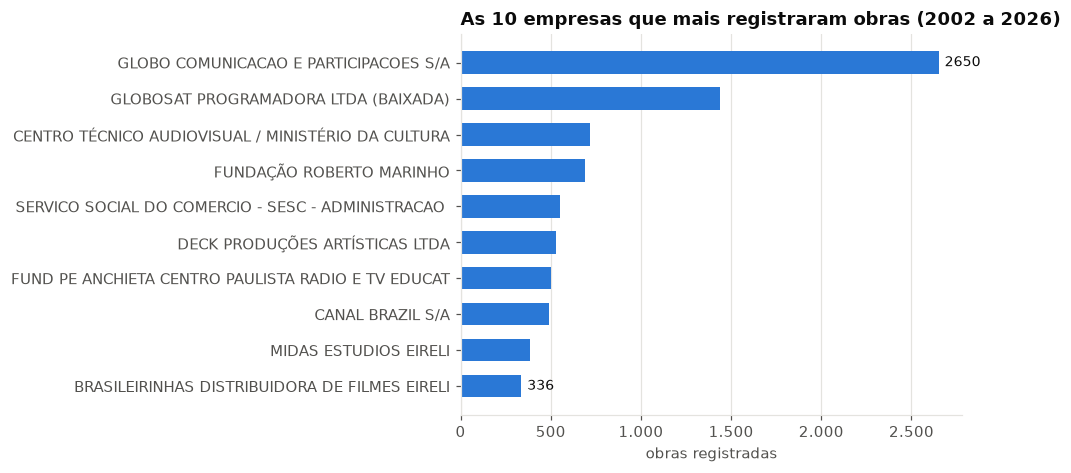

In [15]:
barras_horizontais([n[:50] for n in r3["razao_social"]], list(r3["obras"]),
                   "As 10 empresas que mais registraram obras (2002 a 2026)", "obras registradas",
                   destaques=(0, 9))

**Análise.** A produção registrada é pouco concentrada: as 10 maiores requerentes somam 13,11% das 63.255 obras, entre 8.180 empresas que registraram ao menos uma obra. O topo é dominado pela televisão e por instituições, e não por produtoras de cinema: a GLOBO COMUNICACAO E PARTICIPACOES S/A sozinha tem 2.650 obras (4,19%), seguida da GLOBOSAT (1.436), do Centro Técnico Audiovisual do Ministério da Cultura (719) e da Fundação Roberto Marinho (688). Nenhuma das 10 tem nível de produtora independente cadastrado (coluna `nivel` igual a `sem classificação`), ou seja, os maiores volumes vêm de agentes fora da classificação de produtora independente.

### 6.2.2 Consulta 4

**Pergunta (investigação IV).** Que parcela das obras destinadas às salas de exibição recebeu fomento indireto, por
tipo de obra?

**Como o SQL responde.** Junção externa à esquerda de `obra` com `obra_fomento`, para manter as obras sem fomento.
Como uma obra pode ter mais de um projeto, a expressão de tabela `obra_com_fomento` agrupa a junção por obra e marca se
ela tem algum projeto. A seleção restringe ao segmento salas de exibição, e duas partes unidas por `UNION ALL`
calculam os totais das obras para salas e das demais, que ficam no fim da tabela. A
última coluna repete a fatia só para obras com CPB a partir de 2015: antes de 2014 o segmento de destinação quase
sempre vinha como `INDEFINIDO`, e as poucas obras marcadas para salas eram justamente as que tinham projeto de
fomento.

In [16]:
q4 = """
WITH obra_com_fomento AS (
    SELECT o.cpb, o.tipo,
           o.segmento_destinacao = 'SALAS DE EXIBIÇÃO' AS para_salas,
           o.data_emissao_cpb >= '2015' AS desde_2015,
           MAX(f.cpb IS NOT NULL) AS fomentada
    FROM obra o
    LEFT JOIN obra_fomento f ON f.cpb = o.cpb
    GROUP BY o.cpb
),
resumo AS (
SELECT tipo, COUNT(*) AS obras, SUM(fomentada) AS com_fomento,
       ROUND(100.0 * SUM(fomentada) / COUNT(*), 1) AS pct_com_fomento,
       ROUND(100.0 * SUM(fomentada AND desde_2015) / SUM(desde_2015), 1) AS pct_desde_2015
FROM obra_com_fomento WHERE para_salas GROUP BY tipo
UNION ALL
SELECT 'TOTAL (salas de exibição)', COUNT(*), SUM(fomentada), ROUND(100.0 * SUM(fomentada) / COUNT(*), 1),
       ROUND(100.0 * SUM(fomentada AND desde_2015) / SUM(desde_2015), 1)
FROM obra_com_fomento WHERE para_salas
UNION ALL
SELECT 'TOTAL (demais segmentos)', COUNT(*), SUM(fomentada), ROUND(100.0 * SUM(fomentada) / COUNT(*), 1),
       ROUND(100.0 * SUM(fomentada AND desde_2015) / SUM(desde_2015), 1)
FROM obra_com_fomento WHERE NOT para_salas
)
SELECT * FROM resumo
ORDER BY tipo LIKE 'TOTAL%', tipo = 'TOTAL (demais segmentos)', obras DESC
"""
r4 = sql(q4)
r4

,tipo,obras,com_fomento,pct_com_fomento,pct_desde_2015
0,FICÇÃO,3774,973,25.8,19.4
1,DOCUMENTÁRIO,2691,467,17.4,13.3
2,ANIMAÇÃO,533,42,7.9,6.4
3,VÍDEOMUSICAL,78,0,0.0,0.0
4,VARIEDADES,24,0,0.0,0.0
5,JORNALÍSTICA,7,0,0.0,0.0
6,TOTAL (salas de exibição),7107,1482,20.9,15.7
7,TOTAL (demais segmentos),56148,1620,2.9,3.0


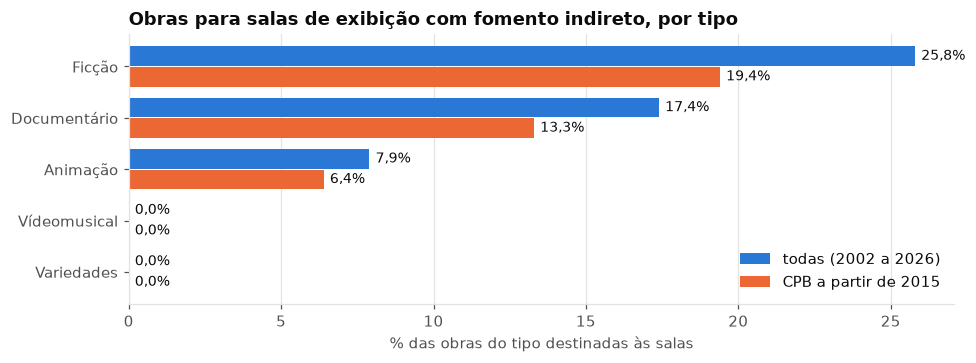

In [17]:
g4 = r4[~r4["tipo"].str.startswith("TOTAL") & (r4["obras"] >= 20)].sort_values("pct_com_fomento", ascending=False)
fig, ax = plt.subplots(figsize=(9, 3.4))
pos = list(range(len(g4)))[::-1]
ax.barh([p + 0.2 for p in pos], g4["pct_com_fomento"], height=0.38, color=AZUL, label="todas (2002 a 2026)")
ax.barh([p - 0.2 for p in pos], g4["pct_desde_2015"], height=0.38, color=LARANJA, label="CPB a partir de 2015")
ax.set_yticks(pos, g4["tipo"].str.title())
ax.grid(axis="y", visible=False)
for p, a, b in zip(pos, g4["pct_com_fomento"], g4["pct_desde_2015"]):
    ax.annotate(f"{a:.1f}%".replace(".", ","), (a, p + 0.2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
    ax.annotate(f"{b:.1f}%".replace(".", ","), (b, p - 0.2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xlabel("% das obras do tipo destinadas às salas")
ax.set_title("Obras para salas de exibição com fomento indireto, por tipo")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**Análise.** Das 7.107 obras destinadas às salas de exibição, 1.482 (20,9%) receberam fomento indireto, contra apenas 2,9% das 56.148 obras dos demais segmentos: o incentivo fiscal federal se concentra no cinema de sala. Ficção é o tipo mais fomentado (25,8%), seguido de documentário (17,4%) e animação (7,9%); videomusicais e variedades para salas não têm nenhum projeto. Considerando só os CPBs a partir de 2015, quando o segmento passou a ser informado para quase todas as obras, a fatia cai para 15,7% (ficção 19,4%, documentário 13,3%, animação 6,4%), o que mostra que a taxa histórica é inflada pelos anos em que só obras fomentadas declaravam o segmento.

### 6.2.3 Consulta 5

**Pergunta (investigação III).** Em quantos municípios há cinema em funcionamento e quais concentram mais complexos?

**Como o SQL responde.** Junção de `complexo` com `municipio`, selecionando os complexos em funcionamento e agrupando
por município. Funções de janela calculadas antes do `LIMIT` dão o número de municípios com cinema
(`COUNT(*) OVER ()`), o total de complexos e a fatia acumulada dos 15 primeiros.

In [18]:
q5 = """
SELECT m.nome AS municipio, m.uf, COUNT(*) AS complexos,
       ROUND(100.0 * SUM(COUNT(*)) OVER (ORDER BY COUNT(*) DESC, m.nome ROWS UNBOUNDED PRECEDING)
             / SUM(COUNT(*)) OVER (), 1) AS pct_acumulado,
       COUNT(*) OVER () AS municipios_com_cinema,
       SUM(COUNT(*)) OVER () AS complexos_no_pais
FROM complexo c
JOIN municipio m ON m.id_municipio = c.id_municipio
WHERE c.situacao = 'EM FUNCIONAMENTO'
GROUP BY m.id_municipio
ORDER BY complexos DESC, m.nome
LIMIT 15
"""
r5 = sql(q5)
r5

,municipio,uf,complexos,pct_acumulado,municipios_com_cinema,complexos_no_pais
0,SÃO PAULO,SP,104,10.0,510,1042
1,RIO DE JANEIRO,RJ,49,14.7,510,1042
2,BELO HORIZONTE,MG,21,16.7,510,1042
3,CURITIBA,PR,21,18.7,510,1042
4,BRASÍLIA,DF,19,20.5,510,1042
5,MANAUS,AM,19,22.4,510,1042
6,RECIFE,PE,17,24.0,510,1042
7,SALVADOR,BA,16,25.5,510,1042
8,GOIÂNIA,GO,14,26.9,510,1042
9,PORTO ALEGRE,RS,14,28.2,510,1042


**Análise.** Apenas 510 municípios têm ao menos um complexo de cinema em funcionamento, menos de 10% dos 5.570 municípios brasileiros, somando 1.042 complexos. A cidade de São Paulo sozinha tem 104 complexos (10,0% do país) e o Rio de Janeiro, 49; os 15 municípios da lista, 13 deles capitais, concentram 32,1% dos complexos. Manaus, com 19 complexos, empata com Brasília e fica à frente de Recife e Salvador, um destaque regional.

## 6.3 Três consultas envolvendo junção de três ou mais relações

### 6.3.1 Consulta 6

**Pergunta (investigação I).** Como a pandemia afetou o registro de obras em cada UF? Compara-se 2019 (antes), 2020 e
2021 (pandemia) e 2025 (último ano completo).

**Como o SQL responde.** A UF de uma obra vem do município da empresa requerente ou, se o requerente é pessoa física,
do município associado à obra. Por isso a consulta junta `obra`, `empresa` e duas ocorrências de `municipio` (junções
externas), e usa `COALESCE` para escolher a UF. Somas condicionais contam as obras por UF em cada ano, e as variações em
relação a 2019 são calculadas em porcentagem. Ficam as UFs com pelo menos 50 obras em 2019.

In [19]:
q6 = """
WITH obra_uf AS (
    SELECT substr(o.data_emissao_cpb, 1, 4) AS ano, COALESCE(me.uf, mp.uf) AS uf
    FROM obra o
    LEFT JOIN empresa e ON e.cnpj = o.cnpj_requerente
    LEFT JOIN municipio me ON me.id_municipio = e.id_municipio
    LEFT JOIN municipio mp ON mp.id_municipio = o.id_municipio_requerente_pf
),
por_uf AS (
    SELECT uf, SUM(ano = '2019') AS obras_2019, SUM(ano = '2020') AS obras_2020,
           SUM(ano = '2021') AS obras_2021, SUM(ano = '2025') AS obras_2025
    FROM obra_uf
    GROUP BY uf
)
SELECT *, ROUND(100.0 * (obras_2020 - obras_2019) / obras_2019, 1) AS var_2019_2020_pct,
          ROUND(100.0 * (obras_2025 - obras_2019) / obras_2019, 1) AS var_2019_2025_pct
FROM por_uf
WHERE obras_2019 >= 50
ORDER BY obras_2019 DESC, uf
"""
r6 = sql(q6)
r6

,uf,obras_2019,obras_2020,obras_2021,obras_2025,var_2019_2020_pct,var_2019_2025_pct
0,SP,1424,1100,1318,1419,-22.8,-0.4
1,RJ,1081,1006,1114,971,-6.9,-10.2
2,RS,166,153,159,258,-7.8,55.4
3,BA,125,102,87,173,-18.4,38.4
4,MG,125,131,106,228,4.8,82.4
5,DF,92,46,108,87,-50.0,-5.4
6,PR,92,84,88,101,-8.7,9.8
7,SC,78,69,72,111,-11.5,42.3
8,GO,72,44,43,79,-38.9,9.7
9,PE,66,59,53,112,-10.6,69.7


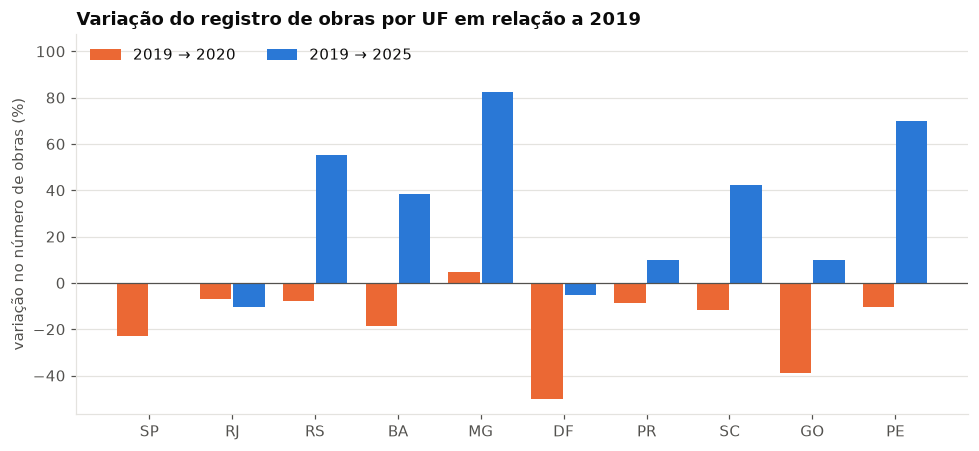

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = range(len(r6))
ax.bar([i - 0.2 for i in x], r6["var_2019_2020_pct"], width=0.38, color=LARANJA, label="2019 → 2020")
ax.bar([i + 0.2 for i in x], r6["var_2019_2025_pct"], width=0.38, color=AZUL, label="2019 → 2025")
ax.axhline(0, color=TINTA_2, linewidth=0.8)
ax.set_xticks(list(x), r6["uf"])
ax.grid(axis="x", visible=False)
ax.set_ylabel("variação no número de obras (%)")
ax.set_title("Variação do registro de obras por UF em relação a 2019")
ax.set_ylim(top=max(r6["var_2019_2025_pct"].max(), r6["var_2019_2020_pct"].max()) + 25)
ax.legend(loc="upper left", ncols=2)
fig.tight_layout()
plt.show()

**Análise.** A queda de 2020 foi desigual entre as UFs: São Paulo perdeu 22,8% dos registros (1.424 para 1.100), Goiás 38,9% e o Distrito Federal 50,0%, enquanto o Rio de Janeiro caiu só 6,9% e Minas Gerais até cresceu 4,8%. A recuperação também mudou o mapa: em 2025, São Paulo voltou ao nível de 2019 (-0,4%) e o Rio ficou 10,2% abaixo, mas Minas (+82,4%), Pernambuco (+69,7%), Rio Grande do Sul (+55,4%), Santa Catarina (+42,3%) e Bahia (+38,4%) passaram bem do patamar pré-pandemia. O crescimento pós-pandemia veio, portanto, de fora do eixo Rio-São Paulo, que ainda responde pela maior parte dos registros.

### 6.3.2 Consulta 7

**Pergunta (investigação II).** Em que segmentos da cadeia audiovisual atuam as empresas que registram obras? Elas só
produzem, ou também distribuem, exibem e programam?

**Como o SQL responde.** Junção de três relações: `obra` com `empresa_atividade` pelo CNPJ do requerente, e esta com
`atividade_economica`, que traz o segmento de cada atividade. O agrupamento por segmento conta empresas e obras
**distintas** (uma empresa tem várias atividades, e sem o `DISTINCT` cada obra seria contada uma vez por atividade). A
fatia é calculada sobre as obras cujo requerente tem atividades cadastradas, de duas formas: considerando qualquer
atividade da empresa e só a atividade principal. Uma obra pode contar em mais de um segmento, então as fatias não somam
100%.

In [21]:
q7 = """
SELECT a.segmento,
       COUNT(DISTINCT ea.cnpj) AS empresas,
       COUNT(DISTINCT o.cpb) AS obras,
       ROUND(100.0 * COUNT(DISTINCT o.cpb) / base.obras, 1) AS pct_obras,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN ea.classificacao = 'PRINCIPAL' THEN o.cpb END) / base.obras, 1)
           AS pct_obras_atividade_principal
FROM obra o
JOIN empresa_atividade ea ON ea.cnpj = o.cnpj_requerente
JOIN atividade_economica a ON a.id_atividade = ea.id_atividade
CROSS JOIN (SELECT COUNT(DISTINCT o2.cpb) AS obras
            FROM obra o2 JOIN empresa_atividade ea2 ON ea2.cnpj = o2.cnpj_requerente) AS base
GROUP BY a.segmento
ORDER BY obras DESC
"""
r7 = sql(q7)
r7

,segmento,empresas,obras,pct_obras,pct_obras_atividade_principal
0,Outras,4237,30497,88.7,30.5
1,Produção,4510,30292,88.1,60.6
2,Distribuição,1744,16939,49.3,0.6
3,Programação e TV,220,8462,24.6,16.0
4,Exibição,767,5205,15.1,0.1


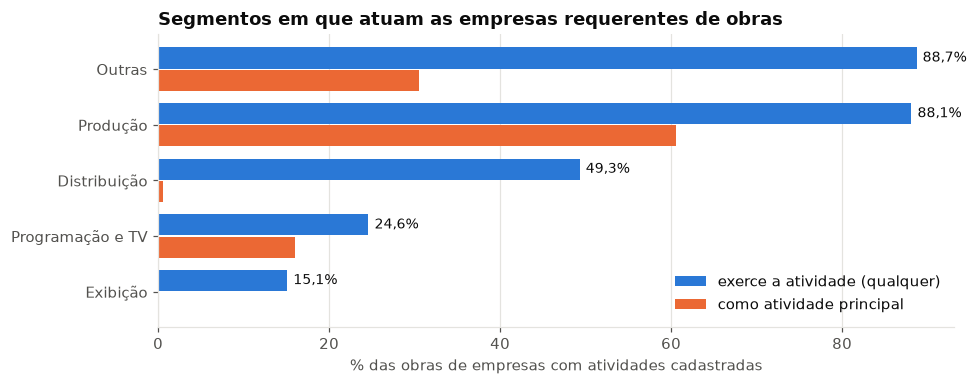

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.6))
pos = list(range(len(r7)))[::-1]
ax.barh([p + 0.2 for p in pos], r7["pct_obras"], height=0.38, color=AZUL, label="exerce a atividade (qualquer)")
ax.barh([p - 0.2 for p in pos], r7["pct_obras_atividade_principal"], height=0.38, color=LARANJA,
        label="como atividade principal")
ax.set_yticks(pos, r7["segmento"])
ax.grid(axis="y", visible=False)
for p, v in zip(pos, r7["pct_obras"]):
    ax.annotate(f"{v:.1f}%".replace(".", ","), (v, p + 0.2), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9)
ax.set_xlabel("% das obras de empresas com atividades cadastradas")
ax.set_title("Segmentos em que atuam as empresas requerentes de obras")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**Análise.** Quase todas as obras de empresas com atividades cadastradas vêm de requerentes que exercem produção (88,1%), mas 88,7% delas vêm de empresas que também exercem atividades fora do audiovisual (segmento "Outras", como publicidade, eventos e ensino), sinal de que as produtoras são em geral empresas diversificadas. A integração vertical aparece como atividade secundária: 49,3% das obras são de empresas que também têm distribuição cadastrada e 15,1% de empresas com exibição, embora quase nenhuma tenha esses segmentos como atividade principal (0,6% e 0,1%). Programação e TV é o único segmento além da produção com peso como atividade principal (16,0% das obras), puxado pelas emissoras e programadoras vistas na Consulta 3.

### 6.3.3 Consulta 8

**Pergunta (investigação III).** Quão concentrado é o parque exibidor em funcionamento entre os grupos exibidores?

**Como o SQL responde.** Junção de `sala`, `complexo` e `empresa` (o grupo exibidor é atributo da empresa exibidora).
A seleção mantém as salas em funcionamento; o agrupamento por grupo soma complexos, salas e assentos. Exibidores sem
grupo aparecem juntos na linha "sem grupo". Janelas calculadas antes do `LIMIT` dão a fatia de assentos de cada grupo e
o número total de grupos.

In [23]:
q8 = """
SELECT COALESCE(e.grupo_exibidor, '(sem grupo)') AS grupo_exibidor,
       COUNT(DISTINCT c.registro_complexo) AS complexos, COUNT(*) AS salas, SUM(s.assentos) AS assentos,
       ROUND(100.0 * SUM(s.assentos) / SUM(SUM(s.assentos)) OVER (), 1) AS pct_assentos,
       COUNT(*) OVER () - 1 AS grupos_no_pais
FROM sala s
JOIN complexo c ON c.registro_complexo = s.registro_complexo
JOIN empresa e ON e.cnpj = c.cnpj_exibidor
WHERE s.situacao = 'EM FUNCIONAMENTO'
GROUP BY e.grupo_exibidor
ORDER BY assentos DESC
LIMIT 12
"""
r8 = sql(q8)
r8

,grupo_exibidor,complexos,salas,assentos,pct_assentos,grupos_no_pais
0,CINEMARK,85,620,136454,19.2,69
1,(sem grupo),350,521,92124,13.0,69
2,CINÉPOLIS,57,414,79119,11.1,69
3,KINOPLEX,33,190,38355,5.4,69
4,ARAÚJO,30,160,35110,4.9,69
5,CINESYSTEM,28,170,34710,4.9,69
6,UCI,17,144,30366,4.3,69
7,CINEFLIX,25,129,21918,3.1,69
8,GRUPO CINE,32,109,17851,2.5,69
9,MOVIECOM,19,95,16877,2.4,69


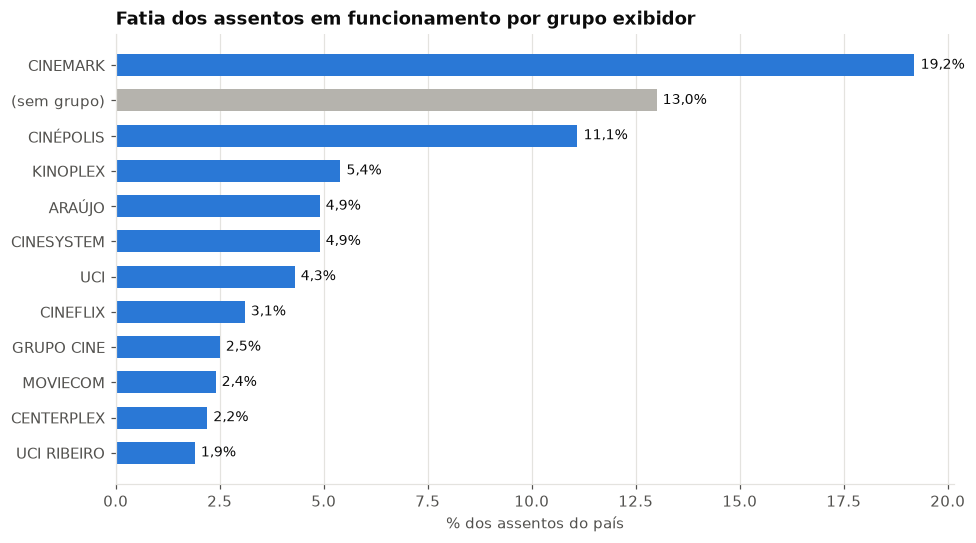

In [24]:
cores8 = [CINZA if g == "(sem grupo)" else AZUL for g in r8["grupo_exibidor"]]
barras_horizontais(list(r8["grupo_exibidor"]), list(r8["pct_assentos"]),
                   "Fatia dos assentos em funcionamento por grupo exibidor", "% dos assentos do país",
                   cores=cores8, fmt="{:.1f}%", destaques=range(len(r8)), eixo_milhar=False)

**Análise.** O parque exibidor é concentrado em poucos grupos: dos 69 grupos com salas em funcionamento, Cinemark (19,2% dos assentos, 620 salas), Cinépolis (11,1%) e Kinoplex (5,4%) somam 35,7% dos assentos do país. Os exibidores sem grupo têm 13,0% dos assentos, mas espalhados em 350 complexos com média de 1,5 sala cada, contra 7,3 salas por complexo na Cinemark (620 em 85). O modelo dominante é, portanto, o multiplex de rede, e o exibidor independente sobrevive em complexos de uma ou duas salas.

## 6.4 Duas consultas envolvendo agregação sobre junção de duas ou mais relações

### 6.4.1 Consulta 9

**Pergunta (investigação I).** Como evoluiu o registro de obras de 2002 a 2026, separando o tipo de requerente
(empresa brasileira independente, demais empresas e pessoa física)?

**Como o SQL responde.** Junção externa de `obra` com `empresa` e agregação por ano de emissão do CPB, com somas
condicionais por tipo de requerente e uma janela (`LAG`) que calcula a variação do total em relação ao ano anterior.
O ano de 2026 vai só até setembro (última atualização do arquivo). A condição de independente é a do cadastro atual
da empresa, e não a da data do registro da obra; requerentes que não estão no cadastro de agentes regulares ficam em
"demais empresas".

In [25]:
q9 = """
WITH anual AS (
    SELECT CAST(substr(o.data_emissao_cpb, 1, 4) AS INTEGER) AS ano,
           COALESCE(SUM(e.brasileira_independente = 1), 0) AS empresa_independente,
           SUM(o.cnpj_requerente IS NOT NULL AND COALESCE(e.brasileira_independente, 0) = 0) AS demais_empresas,
           SUM(o.cnpj_requerente IS NULL) AS pessoa_fisica,
           COUNT(*) AS total
    FROM obra o
    LEFT JOIN empresa e ON e.cnpj = o.cnpj_requerente
    GROUP BY ano
)
SELECT *, ROUND(100.0 * pessoa_fisica / total, 1) AS pct_pessoa_fisica,
          ROUND(100.0 * (total - LAG(total) OVER (ORDER BY ano)) / LAG(total) OVER (ORDER BY ano), 1) AS var_total_pct
FROM anual
ORDER BY ano
"""
r9 = sql(q9)
r9

,ano,empresa_independente,demais_empresas,pessoa_fisica,total,pct_pessoa_fisica,var_total_pct
0,2002,0,2,0,2,0.0,NaN
1,2003,133,68,0,201,0.0,9950.0
2,2004,198,516,61,775,7.9,285.6
3,2005,826,1748,207,2781,7.4,258.8
4,2006,591,945,215,1751,12.3,-37.0
5,2007,506,1070,209,1785,11.7,1.9
6,2008,553,798,179,1530,11.7,-14.3
7,2009,579,812,234,1625,14.4,6.2
8,2010,673,1152,296,2121,14.0,30.5
9,2011,671,853,394,1918,20.5,-9.6


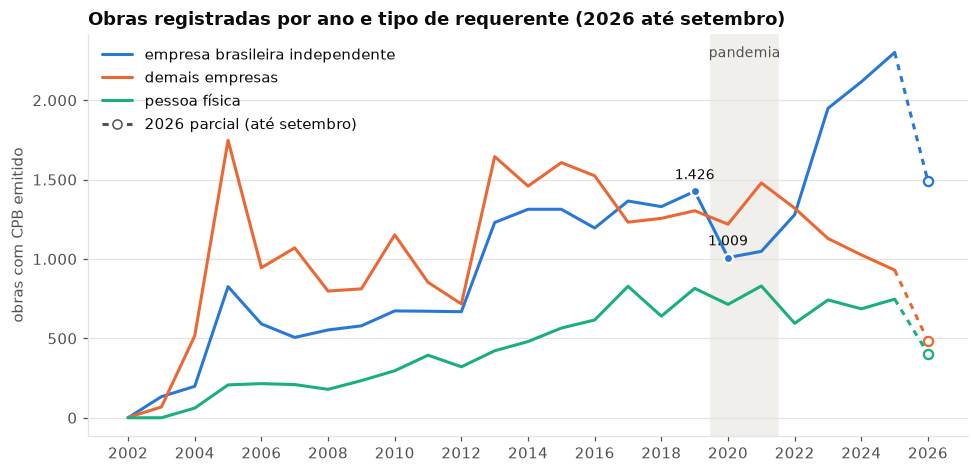

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.axvspan(2019.5, 2021.5, color="#f0efec", zorder=0)
ax.text(2020.5, 0.97, "pandemia", transform=ax.get_xaxis_transform(), ha="center", va="top", color=TINTA_2, fontsize=9)
series = [("empresa_independente", "empresa brasileira independente", AZUL),
          ("demais_empresas", "demais empresas", LARANJA),
          ("pessoa_fisica", "pessoa física", VERDE)]
ultimo = r9["ano"].max()
completos, parcial = r9[r9["ano"] < ultimo], r9[r9["ano"] >= ultimo - 1]
for coluna, nome, cor in series:
    ax.plot(completos["ano"], completos[coluna], color=cor, linewidth=2, label=nome, solid_capstyle="round")
    ax.plot(parcial["ano"], parcial[coluna], color=cor, linewidth=2, linestyle=(0, (2, 2)))
    ax.plot(ultimo, parcial[coluna].iloc[-1], "o", color=cor, markerfacecolor="white", markersize=6,
            markeredgewidth=1.5)
ax.plot([], [], color=TINTA_2, linewidth=2, linestyle=(0, (2, 2)), marker="o", markerfacecolor="white",
        label=f"{ultimo} parcial (até setembro)")
for ano in (2019, 2020):
    v = int(r9.loc[r9["ano"] == ano, "empresa_independente"].iloc[0])
    ax.plot(ano, v, "o", color=AZUL, markersize=6, markeredgecolor="white", markeredgewidth=1.5)
    ax.annotate(f"{v:,}".replace(",", "."), (ano, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(milhar)
ax.set_xticks(range(2002, 2027, 2))
ax.grid(axis="x", visible=False)
ax.set_ylabel("obras com CPB emitido")
ax.set_title("Obras registradas por ano e tipo de requerente (2026 até setembro)")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

**Análise.** O registro de obras cresceu de 201 CPBs em 2003 para o recorde de 3.978 em 2025, com um salto de 93,3% em 2013, que coincide com o início das cotas de conteúdo brasileiro na TV paga (Lei nº 12.485/2011). A pandemia derrubou o total em 17,0% em 2020 (3.545 para 2.942), e o golpe foi maior entre as empresas independentes (1.426 para 1.009, -29,2%) do que entre as demais empresas (-6,5%) e as pessoas físicas (-12,4%); já em 2021 o total voltou a subir 14,1%. De 2023 em diante as independentes registram mais que o dobro das demais empresas (2.301 contra 930 em 2025), mas parte desse efeito é de cadastro: a condição de independente é a atual, e empresas antigas que deixaram de ser agentes regulares caem em "demais empresas".

### 6.4.2 Consulta 10

**Pergunta (investigação III).** Como se distribuem as salas e os assentos em funcionamento por UF, e quanto da lotação
é reservada a cadeirantes?

**Como o SQL responde.** Junção de `sala`, `complexo` e `municipio`, com seleção das salas em funcionamento com
assentos informados, e agregação por UF: salas, assentos, assentos para cadeirantes, percentual sobre a lotação,
número de salas abaixo de 2% e número de salas sem a informação. A ordenação vai da menor para a maior reserva, e a última linha (`UNION ALL`) traz o total do país. Salas sem assentos
informados ou cujo complexo não tem município (itinerantes) ficam de fora; nesta carga isso exclui 1 das 3.722 salas
em funcionamento.

In [27]:
q10 = """
WITH salas_uf AS (
    SELECT m.uf, s.assentos, s.assentos_cadeirantes
    FROM sala s
    JOIN complexo c ON c.registro_complexo = s.registro_complexo
    JOIN municipio m ON m.id_municipio = c.id_municipio
    WHERE s.situacao = 'EM FUNCIONAMENTO' AND s.assentos > 0
),
por_uf AS (
    SELECT uf, COUNT(*) AS salas, SUM(assentos) AS assentos,
           ROUND(100.0 * SUM(assentos) / (SELECT SUM(assentos) FROM salas_uf), 1) AS pct_assentos_pais,
           SUM(assentos_cadeirantes) AS assentos_cadeirantes,
           ROUND(100.0 * SUM(assentos_cadeirantes) / SUM(assentos), 2) AS pct_cadeirantes,
           SUM(1.0 * assentos_cadeirantes / assentos < 0.02) AS salas_abaixo_2pct,
           SUM(assentos_cadeirantes IS NULL) AS salas_sem_informacao
    FROM salas_uf
    GROUP BY uf
    UNION ALL
    SELECT 'BRASIL', COUNT(*), SUM(assentos), 100.0, SUM(assentos_cadeirantes),
           ROUND(100.0 * SUM(assentos_cadeirantes) / SUM(assentos), 2),
           SUM(1.0 * assentos_cadeirantes / assentos < 0.02), SUM(assentos_cadeirantes IS NULL)
    FROM salas_uf
)
SELECT * FROM por_uf
ORDER BY uf = 'BRASIL', pct_cadeirantes
"""
r10 = sql(q10)
r10

,uf,salas,assentos,pct_assentos_pais,assentos_cadeirantes,pct_cadeirantes,salas_abaixo_2pct,salas_sem_informacao
0,DF,89,18254,2.6,273,1.50,43,7
1,SC,159,29611,4.2,514,1.74,77,13
2,MA,63,9882,1.4,175,1.77,25,11
3,GO,124,22463,3.2,399,1.78,54,2
4,RJ,408,76593,10.8,1369,1.79,210,15
5,AC,7,1330,0.2,24,1.80,2,1
6,RS,196,40344,5.7,734,1.82,82,17
7,ES,76,15479,2.2,291,1.88,31,3
8,CE,113,22208,3.1,419,1.89,43,2
9,PR,243,47233,6.7,893,1.89,109,8


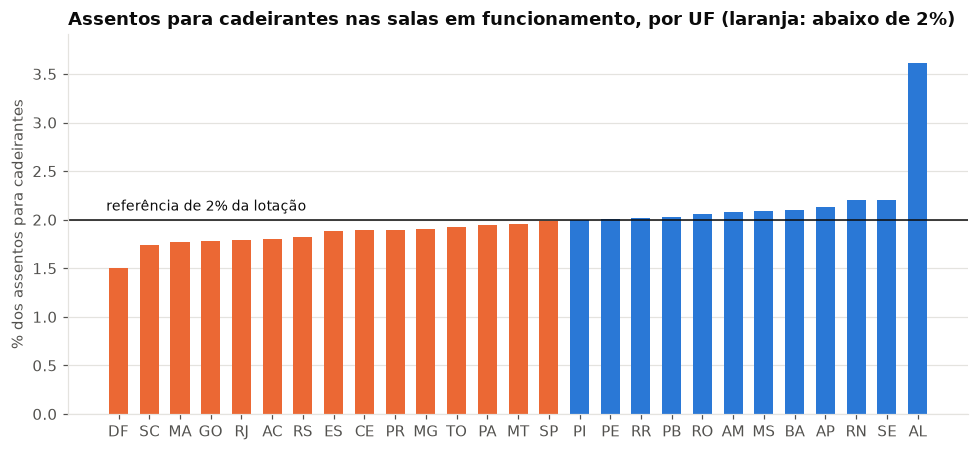

In [28]:
g10 = r10[r10["uf"] != "BRASIL"]
fig, ax = plt.subplots(figsize=(9, 4.2))
cores10 = [LARANJA if v < 2 else AZUL for v in g10["pct_cadeirantes"]]
ax.bar(g10["uf"], g10["pct_cadeirantes"], width=0.62, color=cores10)
ax.axhline(2, color=TINTA, linewidth=1)
ax.text(-0.4, 2.06, "referência de 2% da lotação", ha="left", va="bottom", fontsize=9, color=TINTA)
ax.set_ylim(0, g10["pct_cadeirantes"].max() + 0.3)
ax.grid(axis="x", visible=False)
ax.set_ylabel("% dos assentos para cadeirantes")
ax.set_title("Assentos para cadeirantes nas salas em funcionamento, por UF (laranja: abaixo de 2%)")
fig.tight_layout()
plt.show()

**Análise.** No agregado, o país está quase na referência: 13.731 dos 709.900 assentos em funcionamento (1,93%) são para cadeirantes, e 15 das 27 UFs ficam abaixo de 2%, do Distrito Federal (1,50%) a São Paulo (1,99%). A média, porém, esconde as salas: 1.553 das 3.721 salas (41,7%) têm reserva abaixo de 2% e outras 123 não informam o dado; só em São Paulo são 425 salas abaixo da referência. Alagoas é exceção positiva (3,61%), e o padrão confirma a Consulta 1: salas pequenas com reserva mínima compensam, na média, salas grandes que reservam pouco.

## 6.5 Síntese

- **Evolução e pandemia (Consultas 6 e 9).** O registro de obras caiu 17,0% em 2020, voltou a crescer em 2021 e bateu recorde em 2025 (3.978 CPBs). A queda atingiu mais as produtoras independentes e o Centro-Oeste, e a retomada veio sobretudo de fora do eixo Rio-São Paulo.
- **Concentração da produção (Consultas 3 e 7).** A produção é pulverizada (as 10 maiores requerentes têm 13,11% das obras), com o topo ocupado por televisão e instituições. As produtoras quase sempre têm atividades fora do audiovisual, e metade das obras vem de empresas que também distribuem.
- **Parque exibidor (Consultas 1, 5, 8 e 10).** Só 510 municípios têm cinema, três grupos detêm 35,7% dos assentos, e 41,7% das salas reservam menos de 2% da lotação a cadeirantes, com as maiores salas do país todas abaixo da referência.
- **Fomento indireto (Consultas 2 e 4).** O incentivo federal é do cinema de sala: 15,7% das obras para salas registradas desde 2015 têm projeto, contra 3,0% dos demais segmentos, com a ficção na frente.

## 6.6 Aplicação Streamlit

O arquivo `app.py` é uma aplicação web em Streamlit que lê o `tp2.db` em modo somente leitura e refaz, de forma
interativa, as consultas das quatro investigações. Todo dado vem de SQL executado no SQLite (as consultas ficam em
`consultas.py`), com um marcador `?` para cada valor escolhido na tela; o `pandas` só recebe o resultado e o Altair só
desenha. A tela inicial mostra o modelo (as tuplas por tabela e o diagrama ER), e há uma aba para cada investigação:

- **I. Evolução e pandemia:** obras registradas por ano e tipo de requerente, com intervalo de anos e filtros por tipo
  de obra e por UF, além do total anual com a variação sobre o ano anterior.
- **II. Concentração da produção:** as N empresas que mais registraram obras (N ajustável), com filtro opcional por UF,
  e os segmentos de atividade dessas empresas.
- **III. Parque exibidor:** salas e assentos por UF, a fatia dos grupos exibidores, os assentos para cadeirantes contra
  a referência de 2% e uma tabela ordenável das salas, tudo filtrável por UF.
- **IV. Fomento indireto:** a parcela das obras com fomento por tipo e por ano, com escolha do período e do segmento de
  destinação.

Cada visualização tem um painel "Ver o SQL desta visualização" com a consulta executada e os valores dos marcadores.
O arquivo `test_consultas.py` confere que as consultas do app reproduzem os números citados nas análises acima.

**Como executar.** Depois de executar este notebook, que cria o `tp2.db`, rode na pasta do trabalho:

```
pip install -r requirements.txt
streamlit run app.py
```

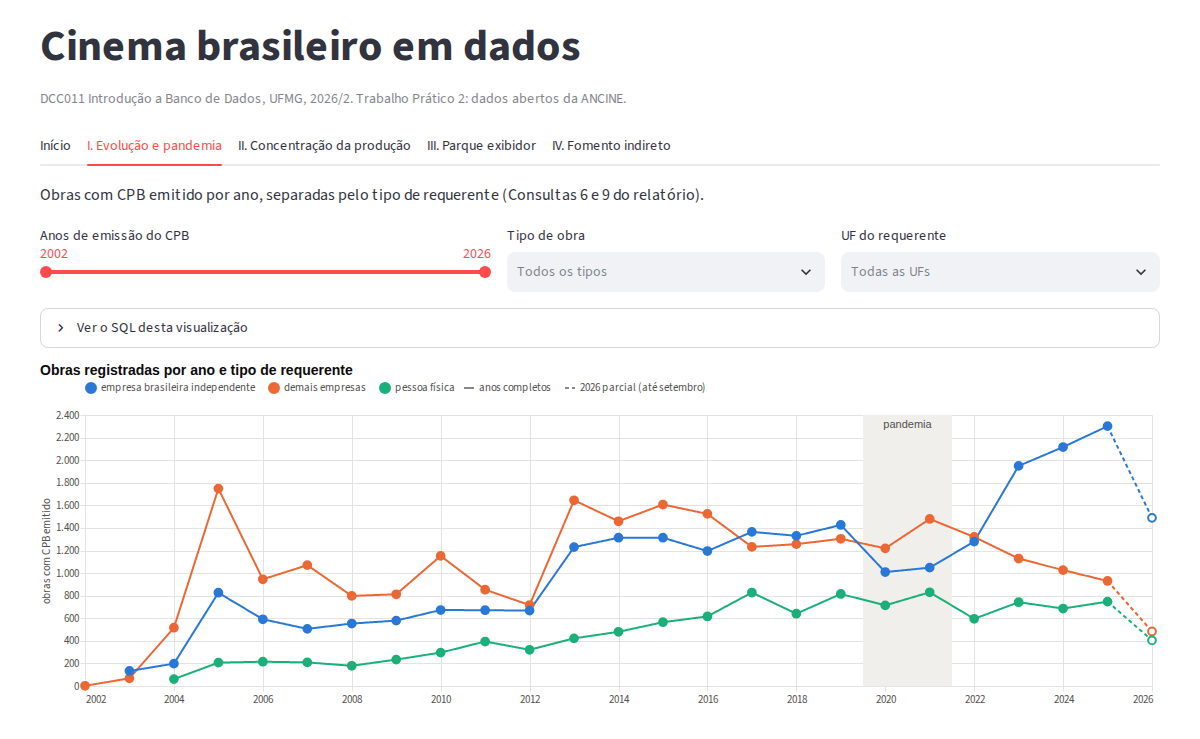

*Aba I, sem filtros: obras por ano e tipo de requerente, com a faixa da pandemia.*

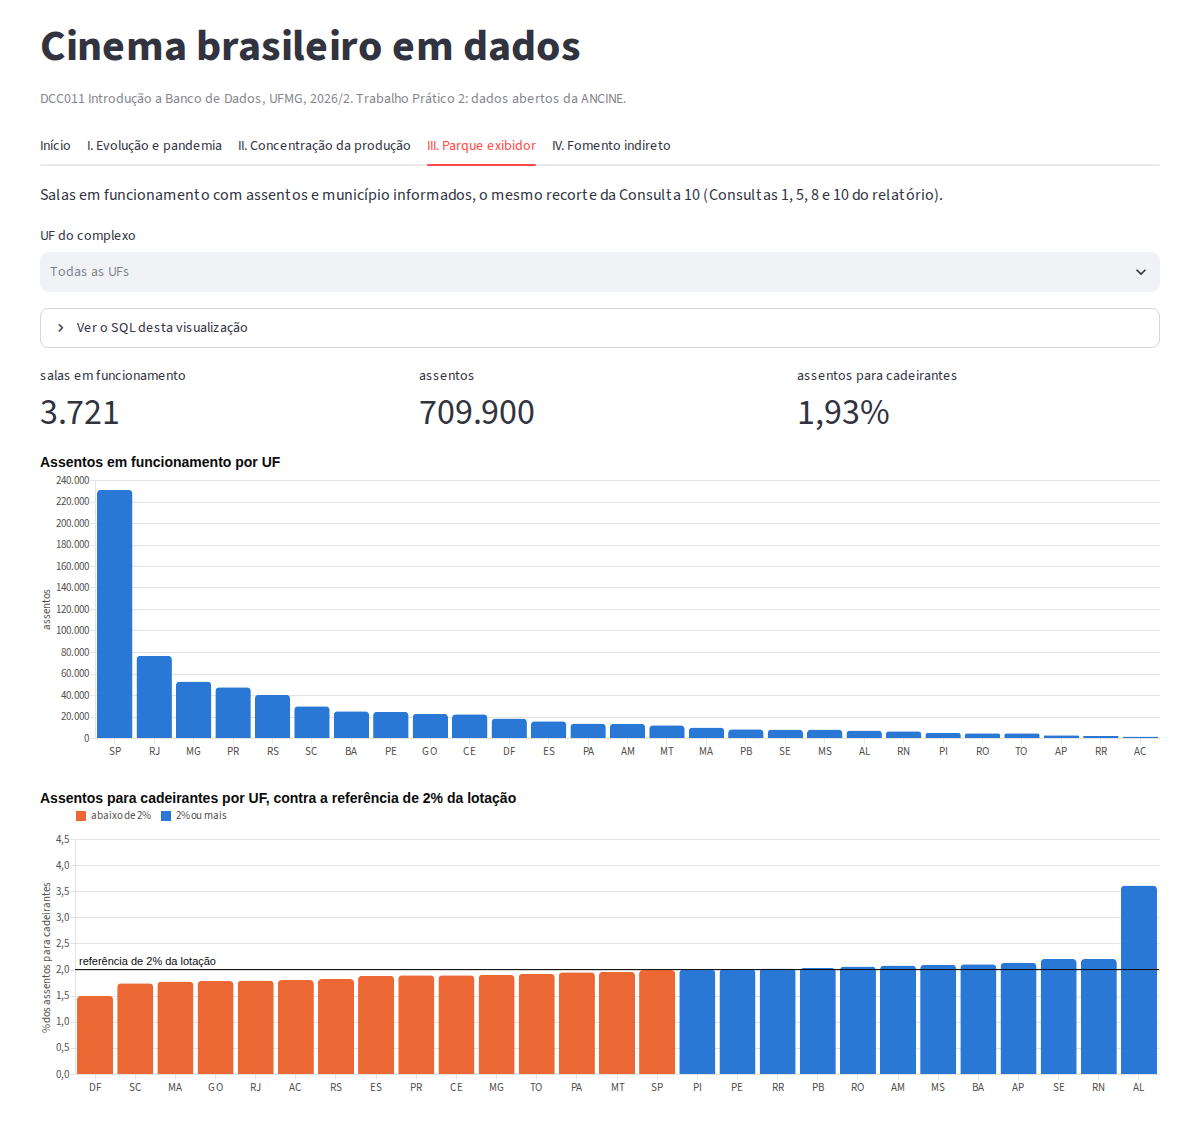

*Aba III, sem filtros: assentos por UF e assentos para cadeirantes contra a referência de 2% da lotação.*

# 7. Autoavaliação dos membros

- Fabrício Chaves da Costa (2022039968): [a preencher]
- [demais membros a confirmar]: [a preencher]

In [29]:
con.close()